# Experiment 4 — Binary Classification using Linear and Kernel-Based Models

### Aim
To classify emails as spam or ham using Logistic Regression and Support Vector Machine (SVM), tune the hyperparameters of both models, and compare how well each one performs.

### Dataset
https://www.kaggle.com/datasets/somesh24/spambase - Spambase dataset -- 57 numeric features taken from email content, plus a `class` column (1 = spam, 0 = ham).


## 1. Setup
Import the libraries used in this notebook.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import time

import warnings
warnings.filterwarnings("ignore")

plt.style.use("default")
sns.set_style("whitegrid")
# Global Plot Formatting (rules.md compliance)
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['legend.fontsize'] = 15


## 2. EDA Helper Functions


In [12]:
# Dataset Overview
def dataset_overview(df):
    print("=" * 80)
    print("DATASET OVERVIEW")
    print("=" * 80)

    print(f"\nRows                : {df.shape[0]}")
    print(f"Columns             : {df.shape[1]}")

    print("\nColumn Names")
    print("-" * 80)

    for col in df.columns:
        print(col)

    print("\nDataset Info")
    print("-" * 80)
    print(df.info())

    print("\nStatistical Summary (Numerical)")
    print("-" * 80)
    print(df.describe().T)

    print("\nStatistical Summary (Categorical)")
    print("-" * 80)

    temp_df = df.select_dtypes(include=["object", "category"])

    if temp_df.shape[1] > 0:
        print(temp_df.describe().T)
    else:
        print("No categorical columns found.")


# Column Analysis
def column_analysis(df):
    print("\n")
    print("=" * 80)
    print("COLUMN ANALYSIS")
    print("=" * 80)

    total_rows = len(df)

    for col in df.columns:
        print("\n" + "-" * 80)
        print(f"Column : {col}")
        print("-" * 80)

        dtype = df[col].dtype
        missing = df[col].isna().sum()
        unique = df[col].nunique(dropna=True)

        print(f"Data Type          : {dtype}")

        if unique <= 20:
            print(df[col].unique())
        else:
            print(df[col].unique()[:20])
            print(f"\nshowing first 20 of {unique} unique values")

        if unique >= 0.95 * total_rows:
            print("Possible Identifier Column")


# Missing Value Analysis
def missing_value_analysis(df):
    print("\n")
    print("=" * 80)
    print("MISSING VALUE ANALYSIS")
    print("=" * 80)

    missing = df.isnull().sum()
    missing_percent = (missing / len(df)) * 100

    missing_df = pd.DataFrame({
        "Missing Count": missing,
        "Missing Percentage": missing_percent
    })

    print(missing_df)

    #Bar Chart
    plt.figure(figsize=(12,5))
    missing_percent.plot(kind="bar")
    plt.ylabel("Missing Percentage")
    plt.title("Missing Values (%)")
    plt.xticks(rotation=90)
    plt.show()


# Duplicate values analysis
def duplicate_analysis(df):
    print("\n")
    print("=" * 80)
    print("DUPLICATE ANALYSIS")
    print("=" * 80)

    duplicates = df.duplicated().sum()
    duplicate_percent = (duplicates / len(df)) * 100

    print(f"Duplicate Rows       : {duplicates}")
    print(f"Duplicate Percentage : {duplicate_percent:.2f}%")

    plt.figure(figsize=(4,4))
    plt.pie(
        [len(df)-duplicates, duplicates],
        labels=["Unique Rows", "Duplicate Rows"],
        autopct="%1.1f%%"
    )

    plt.title("Duplicate Row Distribution")
    plt.show()
# Numerical and Categorical analysis
from scipy import stats

def numerical_analysis(df):
    print("\n")
    print("=" * 80)
    print("NUMERICAL FEATURE ANALYSIS")
    print("=" * 80)

    for col in df.columns:
        if pd.api.types.is_numeric_dtype(df[col]):
            temp = df[col].dropna()
        else:
            temp = pd.to_numeric(df[col], errors="coerce").dropna()
            if len(temp) < 0.9 * df[col].notna().sum():
                continue
        if temp.empty:
            continue

        print("\n" + "-" * 80)
        print(f"Column : {col}")
        print("-" * 80)

        print(f"Mean       : {temp.mean():.3f}")
        print(f"Median     : {temp.median():.3f}")
        print(f"Std Dev    : {temp.std():.3f}")
        print(f"Variance   : {temp.var():.3f}")
        print(f"Skewness   : {temp.skew():.3f}")
        print(f"Kurtosis   : {temp.kurtosis():.3f}")

        # Histogram
        plt.figure(figsize=(6,4))
        plt.hist(temp, bins=30)
        plt.title(f"Histogram : {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.show()

        # Boxplot
        plt.figure(figsize=(6,2))
        sns.boxplot(x=temp)
        plt.title(f"Boxplot : {col}")
        plt.show()

        # Outliers (IQR)
        q1 = temp.quantile(0.25)
        q3 = temp.quantile(0.75)

        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        outliers = ((temp < lower) | (temp > upper)).sum()

        print(f"Outliers Detected : {outliers}")

def categorical_analysis(df):
    print("\n")
    print("=" * 80)
    print("CATEGORICAL FEATURE ANALYSIS")
    print("=" * 80)

    total_rows = len(df.columns)

    for col in df.columns:
        if pd.api.types.is_numeric_dtype(df[col]):
            continue
        temp = pd.to_numeric(df[col], errors="coerce")
        if temp.notna().sum() >= 0.9 * df[col].notna().sum():
            continue
        unique = df[col].nunique(dropna=True)

        print("\n" + "-" * 80)
        print(f"Column : {col}")
        print("-" * 80)
        print(f"Unique Categories : {unique}")
        counts = df[col].value_counts(dropna=False)

        if unique < 0.80 * total_rows:
            if unique <= 20:
                print(counts)
            else:
                print(counts.head(20))
                print(f"\nShowing Top 20 categories out of {unique}")

            plt.figure(figsize=(8,4))
            counts.plot(kind="bar")
            plt.title(col)
            plt.ylabel("Count")
            plt.xticks(rotation=45)
            plt.show()

def correlation_analysis(df):
    print("\n")
    print("=" * 80)
    print("CORRELATION ANALYSIS")
    print("=" * 80)

    numeric_df = df.select_dtypes(include=np.number)

    if numeric_df.shape[1] < 2:
        print("Not enough numerical columns.")
        return []

    corr = numeric_df.corr()

    plt.figure(figsize=(10,8))
    sns.heatmap(
        corr,
        annot=True,
        cmap="coolwarm",
        fmt=".2f"
    )

    plt.title("Correlation Heatmap")
    plt.show()

    print("\nHighly Correlated Feature Pairs")

    high_corr = []
    cols = corr.columns
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            if abs(corr.iloc[i, j]) >= 0.8:
                print(f"{cols[i]}, {cols[j]} = {corr.iloc[i, j]}")
                high_corr.append((cols[i], cols[j], corr.iloc[i, j]))
    return high_corr


def target_analysis(df, task, target):
    print("\n")
    print("=" * 80)
    print("TARGET ANALYSIS")
    print("=" * 80)

    if target is None:
        print("No target provided as parameter!")
        return

    if task.lower() == "classification":
        print(df[target].value_counts())
        plt.figure(figsize=(6,4))
        df[target].value_counts().plot(kind="bar")
        plt.title("Class Distribution")
        plt.show()
    elif task.lower() == "regression":
        print(df[target].describe())
        plt.figure(figsize=(6,4))
        plt.hist(df[target].dropna(), bins=30)
        plt.title("Target Distribution")
        plt.show()


def eda_summary(df, high_corr):
    print("\n")
    print("=" * 80)
    print("FINAL EDA SUMMARY")
    print("=" * 80)

    print(f"Rows                     : {df.shape[0]}")
    print(f"Columns                  : {df.shape[1]}")
    print(f"Numerical Columns        : {len(df.select_dtypes(include=np.number).columns)}")
    print(f"Categorical Columns      : {len(df.select_dtypes(exclude=np.number).columns)}")
    print(f"Duplicate Rows           : {df.duplicated().sum()}")
    print(f"Columns with Missing     : {(df.isnull().sum() > 0).sum()}")
    print(f"Highly Correlated Pairs  : {len(high_corr)}")
    print("\nEDA Completed Successfully.")


# Function to generate 12 EDA subplots on a single consolidated figure (rules.md Section 2 & 4.1)
def plot_eda_12_subplots(df, task="classification", target=None, filename="exp4_eda_12_subplots.eps"):
    fig, axes = plt.subplots(4, 3, figsize=(18, 20))
    axes = axes.flatten()
    
    # 1. Target Distribution
    if target and target in df.columns:
        if task.lower() == "classification":
            counts = df[target].value_counts()
            axes[0].bar([str(c) for c in counts.index], counts.values, color=['skyblue', 'salmon'])
            axes[0].set_title(f"1. Target Distribution ({target})")
            axes[0].set_xlabel(target)
            axes[0].set_ylabel("Count")
        else:
            axes[0].hist(df[target].dropna(), bins=30, color='skyblue', edgecolor='black')
            axes[0].set_title(f"1. Target Distribution ({target})")
            axes[0].set_xlabel(target)
            axes[0].set_ylabel("Frequency")
    else:
        axes[0].text(0.5, 0.5, "No Target Specified", ha='center', va='center')
        axes[0].set_title("1. Target Distribution")
    
    # 2. Missing Values
    missing = df.isnull().sum()
    missing_top10 = missing[missing > 0].head(10) if (missing > 0).any() else missing.head(10)
    axes[1].bar(range(len(missing_top10)), missing_top10.values, color='coral')
    axes[1].set_xticks(range(len(missing_top10)))
    axes[1].set_xticklabels(missing_top10.index, rotation=45, ha='right')
    axes[1].set_title("2. Missing Value Count")
    axes[1].set_ylabel("Count")
    
    # 3. Duplicate Rows
    duplicates = df.duplicated().sum()
    uniques = len(df) - duplicates
    axes[2].pie([uniques, duplicates], labels=['Unique', 'Duplicates'], autopct='%1.1f%%', colors=['lightgreen', 'orange'])
    axes[2].set_title("3. Duplicate Row Ratio")
    
    # Select numeric columns excluding target
    num_cols = [c for c in df.select_dtypes(include=np.number).columns if c != target]
    
    # 4. Correlation Heatmap of top 6 features
    if len(num_cols) >= 2:
        top_num = num_cols[:6]
        corr = df[top_num].corr()
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=axes[3], cbar=False)
        axes[3].set_title("4. Correlation Heatmap")
    else:
        axes[3].text(0.5, 0.5, "N/A", ha='center', va='center')
        axes[3].set_title("4. Correlation Heatmap")
    
    # 5-12. Feature Distribution Subplots
    for i in range(8):
        ax_idx = i + 4
        if i < len(num_cols):
            col_name = num_cols[i]
            axes[ax_idx].hist(df[col_name].dropna(), bins=20, color='teal', alpha=0.7)
            axes[ax_idx].set_title(f"{ax_idx+1}. Dist: {col_name[:15]}")
            axes[ax_idx].set_xlabel(col_name[:15])
            axes[ax_idx].set_ylabel("Freq")
        else:
            axes[ax_idx].text(0.5, 0.5, "N/A", ha='center', va='center')
            axes[ax_idx].set_title(f"{ax_idx+1}. Feature Plot")
            
    plt.tight_layout()
    plt.savefig(filename, format='eps', dpi=600, bbox_inches='tight')
    plt.show()
    print(f"Consolidated EDA 12-subplot figure saved as '{filename}' at 600 DPI.")


In [13]:
def tabular_eda(df, task, target=None):
    dataset_overview(df)
    column_analysis(df)
    missing_value_analysis(df)
    duplicate_analysis(df)
    numerical_analysis(df)
    categorical_analysis(df)
    high_corr = correlation_analysis(df)
    target_analysis(df, task, target)
    eda_summary(df, high_corr)
    # Generate and export 12-subplot EDA figure per rules.md
    plot_eda_12_subplots(df, task, target, filename='exp4_eda_12_subplots.eps')


## 3. Load Dataset

In [14]:

df = pd.read_csv("dataset\spambase.csv")
df.head()

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_%3B,char_freq_%28,char_freq_%5B,char_freq_%21,char_freq_%24,char_freq_%23,capital_run_length_average,capital_run_length_longest,capital_run_length_total,class
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


## 4. Exploratory Data Analysis
Look at the data before doing anything else -- how big it is, whether it has missing values or duplicate rows, how the two classes (spam/ham) are spread out, and how the individual features look.

DATASET OVERVIEW

Rows                : 4601
Columns             : 58

Column Names
--------------------------------------------------------------------------------
word_freq_make
word_freq_address
word_freq_all
word_freq_3d
word_freq_our
word_freq_over
word_freq_remove
word_freq_internet
word_freq_order
word_freq_mail
word_freq_receive
word_freq_will
word_freq_people
word_freq_report
word_freq_addresses
word_freq_free
word_freq_business
word_freq_email
word_freq_you
word_freq_credit
word_freq_your
word_freq_font
word_freq_000
word_freq_money
word_freq_hp
word_freq_hpl
word_freq_george
word_freq_650
word_freq_lab
word_freq_labs
word_freq_telnet
word_freq_857
word_freq_data
word_freq_415
word_freq_85
word_freq_technology
word_freq_1999
word_freq_parts
word_freq_pm
word_freq_direct
word_freq_cs
word_freq_meeting
word_freq_original
word_freq_project
word_freq_re
word_freq_edu
word_freq_table
word_freq_conference
char_freq_%3B
char_freq_%28
char_freq_%5B
char_freq_%21
char_freq_%24
char_fr

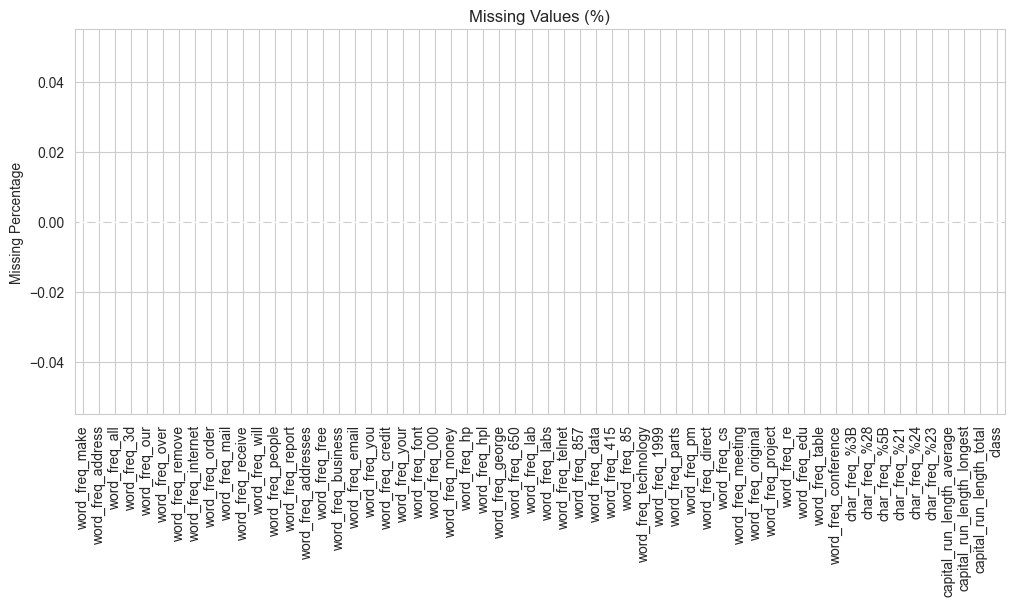



DUPLICATE ANALYSIS
Duplicate Rows       : 391
Duplicate Percentage : 8.50%


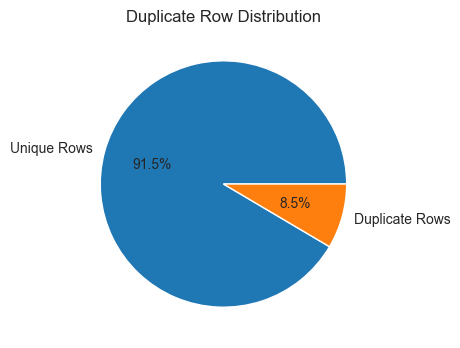



NUMERICAL FEATURE ANALYSIS

--------------------------------------------------------------------------------
Column : word_freq_make
--------------------------------------------------------------------------------
Mean       : 0.105
Median     : 0.000
Std Dev    : 0.305
Variance   : 0.093
Skewness   : 5.676
Kurtosis   : 49.305


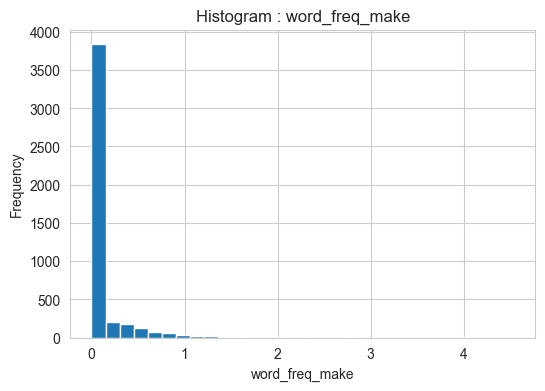

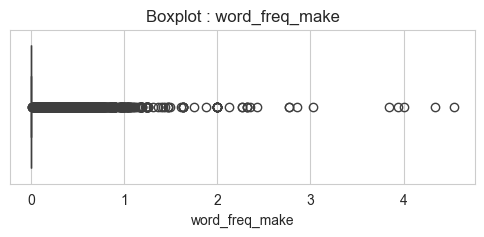

Outliers Detected : 1053

--------------------------------------------------------------------------------
Column : word_freq_address
--------------------------------------------------------------------------------
Mean       : 0.213
Median     : 0.000
Std Dev    : 1.291
Variance   : 1.666
Skewness   : 10.087
Kurtosis   : 105.647


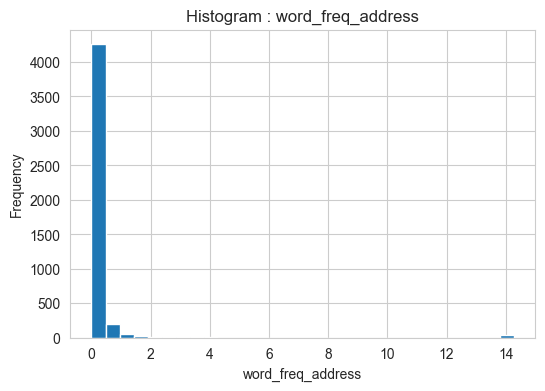

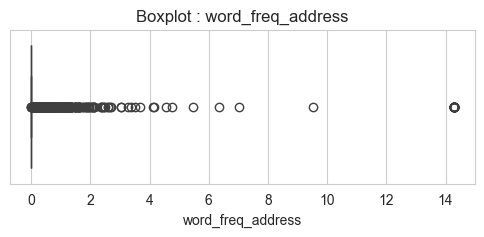

Outliers Detected : 898

--------------------------------------------------------------------------------
Column : word_freq_all
--------------------------------------------------------------------------------
Mean       : 0.281
Median     : 0.000
Std Dev    : 0.504
Variance   : 0.254
Skewness   : 3.009
Kurtosis   : 13.309


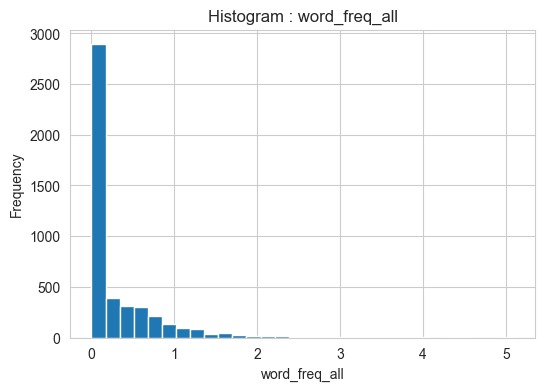

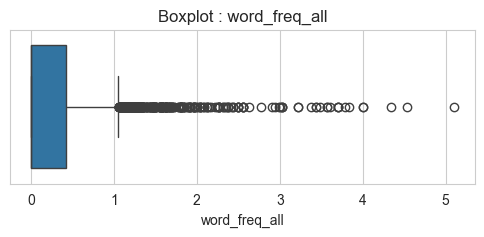

Outliers Detected : 338

--------------------------------------------------------------------------------
Column : word_freq_3d
--------------------------------------------------------------------------------
Mean       : 0.065
Median     : 0.000
Std Dev    : 1.395
Variance   : 1.946
Skewness   : 26.228
Kurtosis   : 726.452


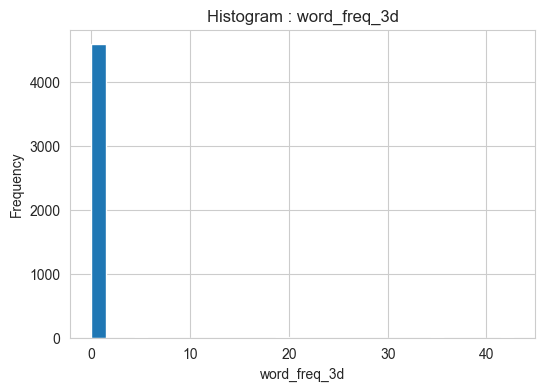

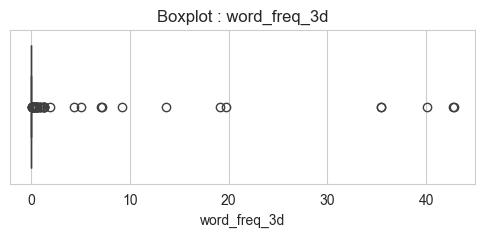

Outliers Detected : 47

--------------------------------------------------------------------------------
Column : word_freq_our
--------------------------------------------------------------------------------
Mean       : 0.312
Median     : 0.000
Std Dev    : 0.673
Variance   : 0.452
Skewness   : 4.747
Kurtosis   : 37.941


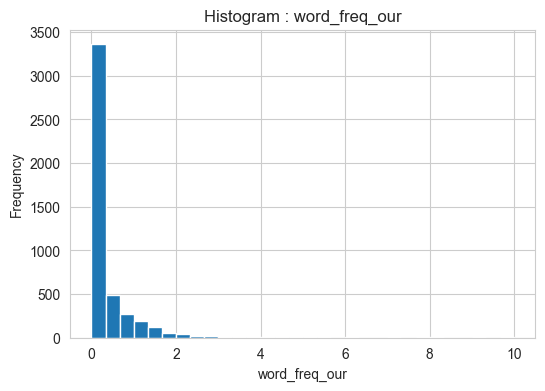

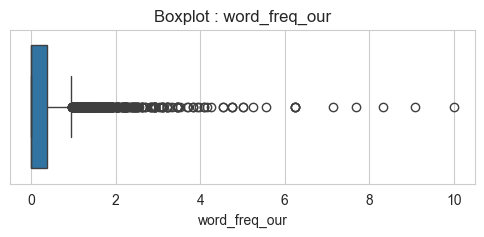

Outliers Detected : 501

--------------------------------------------------------------------------------
Column : word_freq_over
--------------------------------------------------------------------------------
Mean       : 0.096
Median     : 0.000
Std Dev    : 0.274
Variance   : 0.075
Skewness   : 5.957
Kurtosis   : 68.445


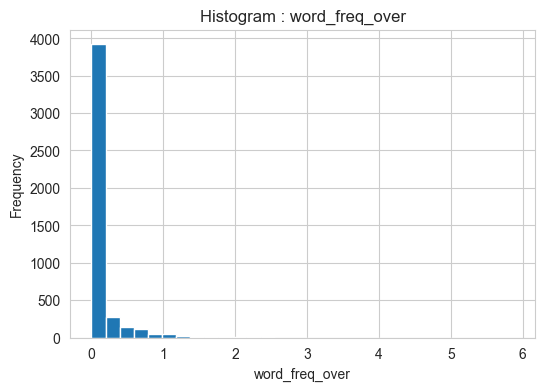

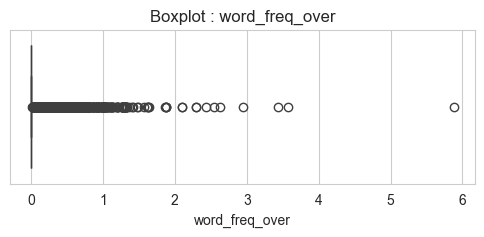

Outliers Detected : 999

--------------------------------------------------------------------------------
Column : word_freq_remove
--------------------------------------------------------------------------------
Mean       : 0.114
Median     : 0.000
Std Dev    : 0.391
Variance   : 0.153
Skewness   : 6.766
Kurtosis   : 75.413


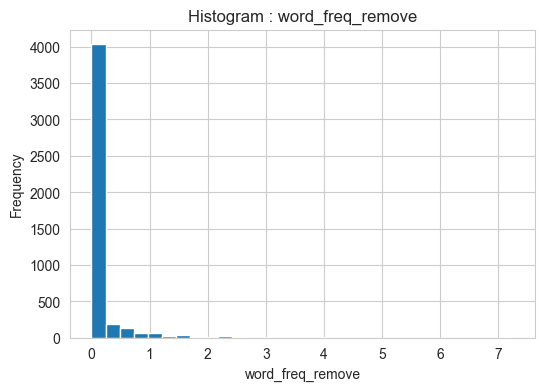

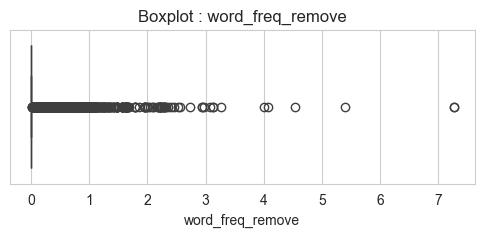

Outliers Detected : 807

--------------------------------------------------------------------------------
Column : word_freq_internet
--------------------------------------------------------------------------------
Mean       : 0.105
Median     : 0.000
Std Dev    : 0.401
Variance   : 0.161
Skewness   : 9.725
Kurtosis   : 169.163


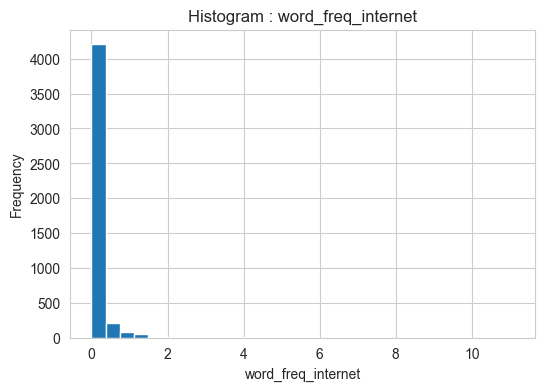

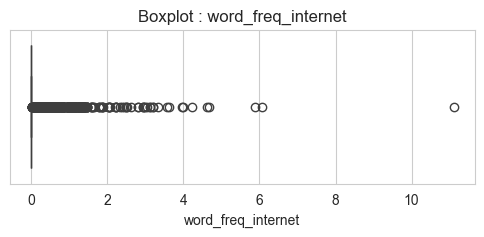

Outliers Detected : 824

--------------------------------------------------------------------------------
Column : word_freq_order
--------------------------------------------------------------------------------
Mean       : 0.090
Median     : 0.000
Std Dev    : 0.279
Variance   : 0.078
Skewness   : 5.226
Kurtosis   : 46.940


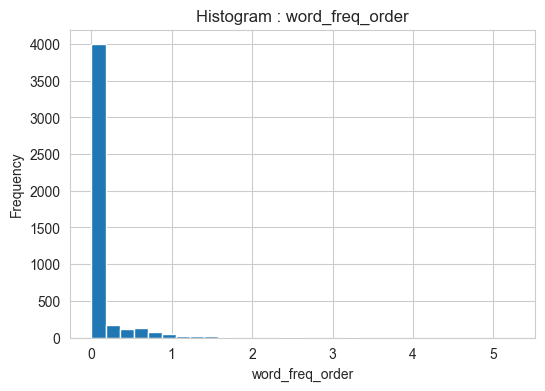

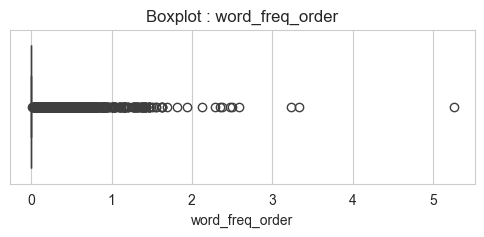

Outliers Detected : 773

--------------------------------------------------------------------------------
Column : word_freq_mail
--------------------------------------------------------------------------------
Mean       : 0.239
Median     : 0.000
Std Dev    : 0.645
Variance   : 0.416
Skewness   : 8.488
Kurtosis   : 161.215


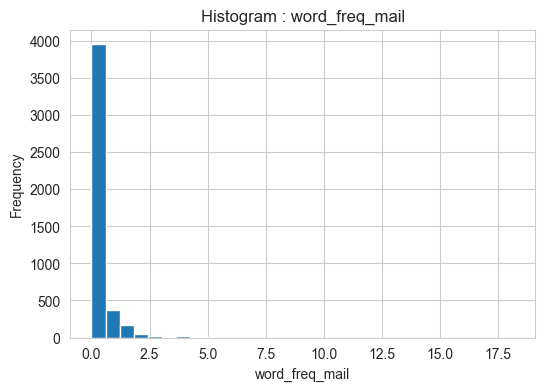

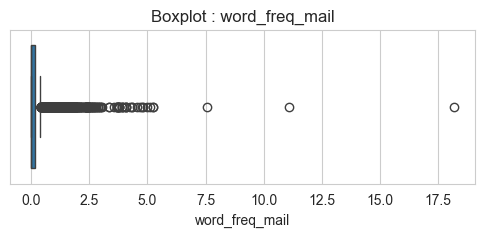

Outliers Detected : 852

--------------------------------------------------------------------------------
Column : word_freq_receive
--------------------------------------------------------------------------------
Mean       : 0.060
Median     : 0.000
Std Dev    : 0.202
Variance   : 0.041
Skewness   : 5.510
Kurtosis   : 39.651


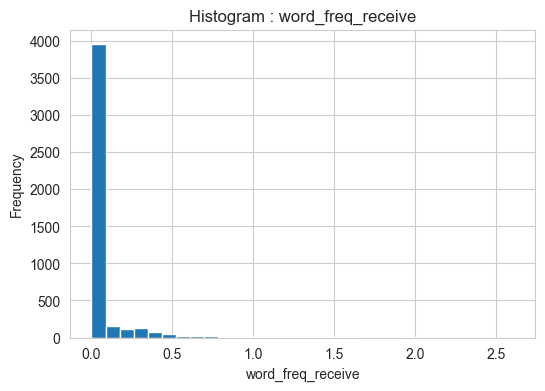

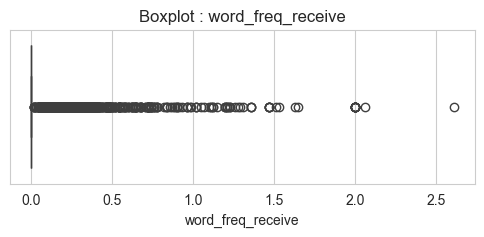

Outliers Detected : 709

--------------------------------------------------------------------------------
Column : word_freq_will
--------------------------------------------------------------------------------
Mean       : 0.542
Median     : 0.100
Std Dev    : 0.862
Variance   : 0.743
Skewness   : 2.867
Kurtosis   : 12.551


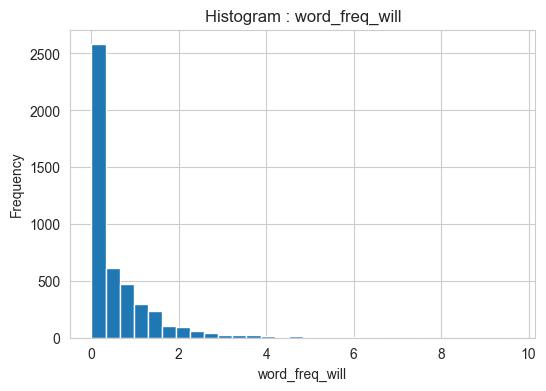

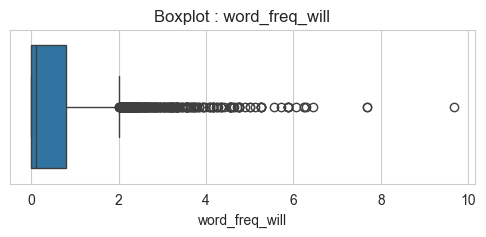

Outliers Detected : 270

--------------------------------------------------------------------------------
Column : word_freq_people
--------------------------------------------------------------------------------
Mean       : 0.094
Median     : 0.000
Std Dev    : 0.301
Variance   : 0.091
Skewness   : 6.956
Kurtosis   : 84.942


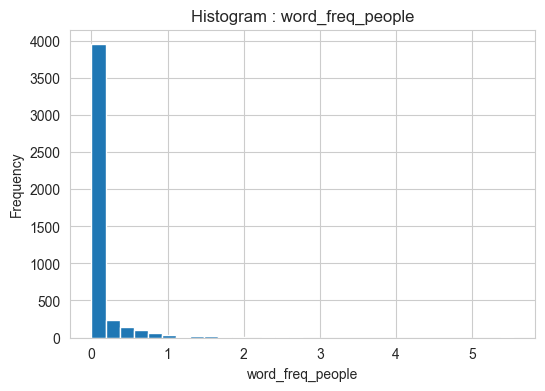

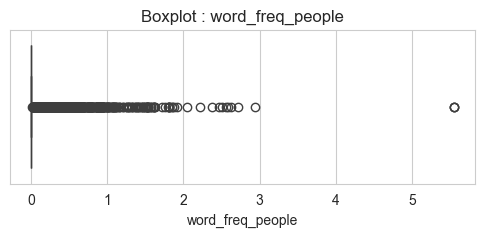

Outliers Detected : 852

--------------------------------------------------------------------------------
Column : word_freq_report
--------------------------------------------------------------------------------
Mean       : 0.059
Median     : 0.000
Std Dev    : 0.335
Variance   : 0.112
Skewness   : 11.755
Kurtosis   : 229.201


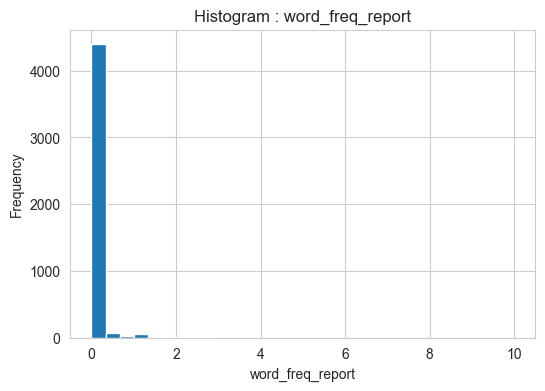

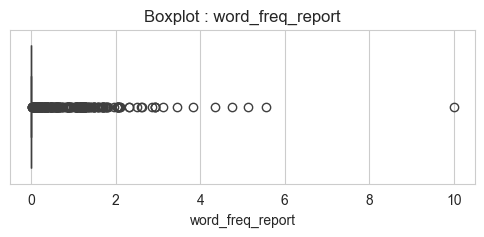

Outliers Detected : 357

--------------------------------------------------------------------------------
Column : word_freq_addresses
--------------------------------------------------------------------------------
Mean       : 0.049
Median     : 0.000
Std Dev    : 0.259
Variance   : 0.067
Skewness   : 6.971
Kurtosis   : 57.728


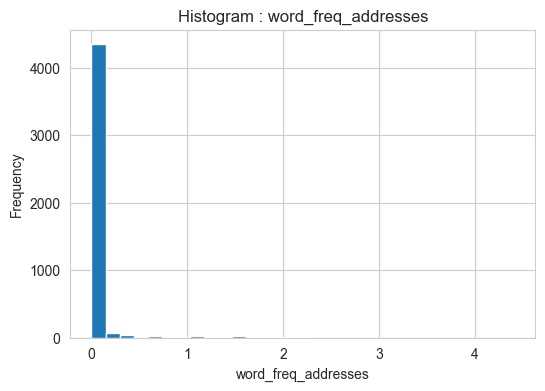

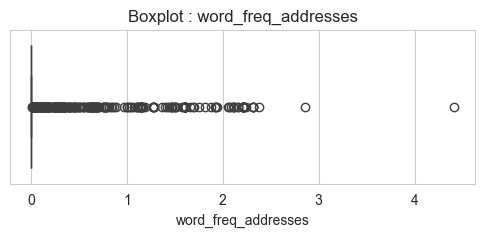

Outliers Detected : 336

--------------------------------------------------------------------------------
Column : word_freq_free
--------------------------------------------------------------------------------
Mean       : 0.249
Median     : 0.000
Std Dev    : 0.826
Variance   : 0.682
Skewness   : 10.764
Kurtosis   : 196.425


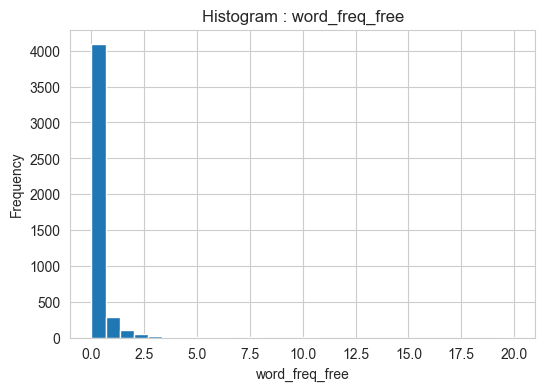

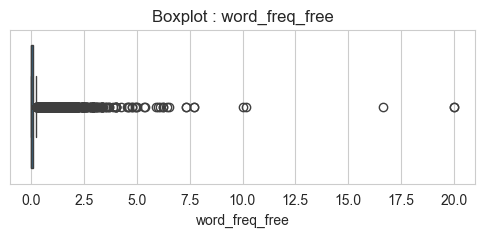

Outliers Detected : 957

--------------------------------------------------------------------------------
Column : word_freq_business
--------------------------------------------------------------------------------
Mean       : 0.143
Median     : 0.000
Std Dev    : 0.444
Variance   : 0.197
Skewness   : 5.689
Kurtosis   : 45.674


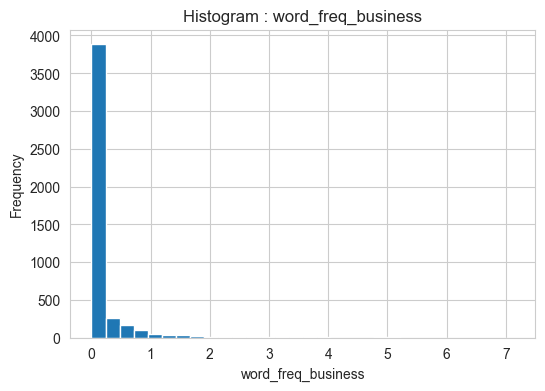

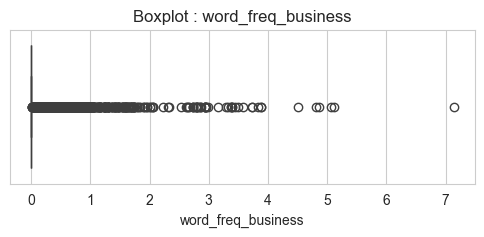

Outliers Detected : 963

--------------------------------------------------------------------------------
Column : word_freq_email
--------------------------------------------------------------------------------
Mean       : 0.185
Median     : 0.000
Std Dev    : 0.531
Variance   : 0.282
Skewness   : 5.414
Kurtosis   : 47.962


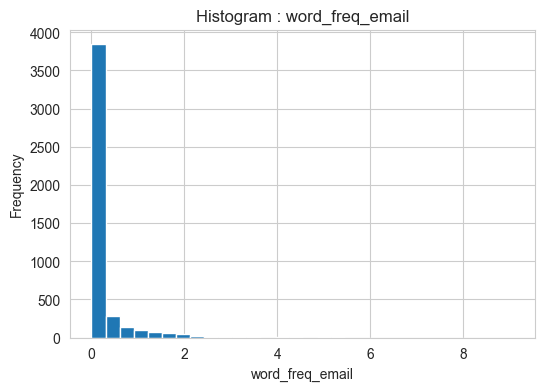

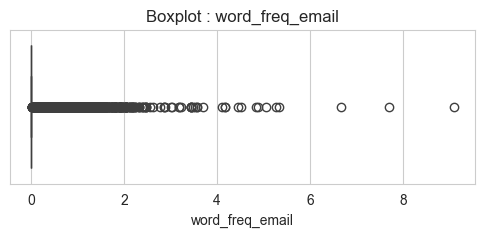

Outliers Detected : 1038

--------------------------------------------------------------------------------
Column : word_freq_you
--------------------------------------------------------------------------------
Mean       : 1.662
Median     : 1.310
Std Dev    : 1.775
Variance   : 3.152
Skewness   : 1.592
Kurtosis   : 5.257


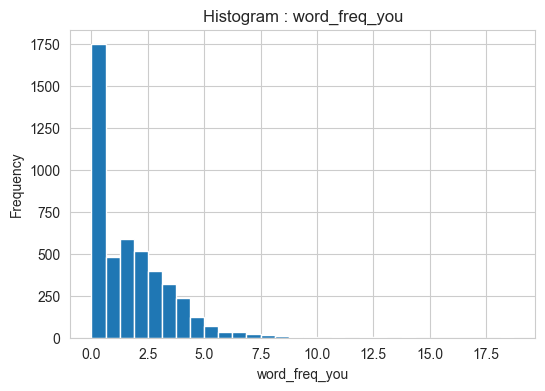

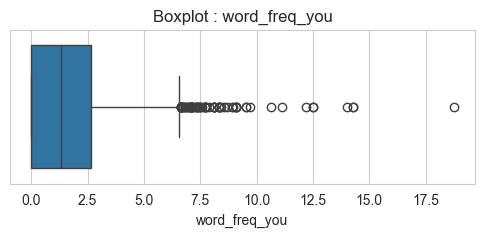

Outliers Detected : 75

--------------------------------------------------------------------------------
Column : word_freq_credit
--------------------------------------------------------------------------------
Mean       : 0.086
Median     : 0.000
Std Dev    : 0.510
Variance   : 0.260
Skewness   : 14.603
Kurtosis   : 383.002


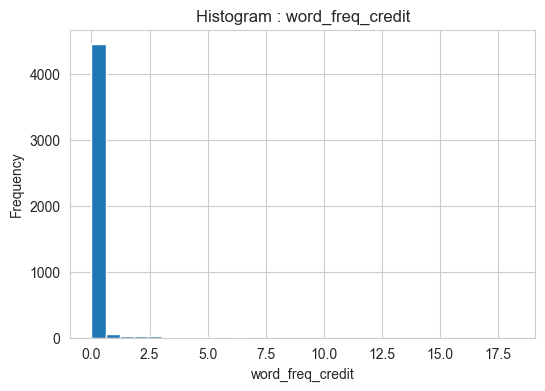

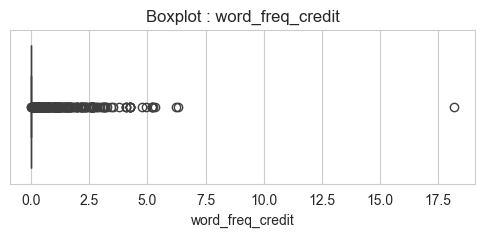

Outliers Detected : 424

--------------------------------------------------------------------------------
Column : word_freq_your
--------------------------------------------------------------------------------
Mean       : 0.810
Median     : 0.220
Std Dev    : 1.201
Variance   : 1.442
Skewness   : 2.436
Kurtosis   : 9.010


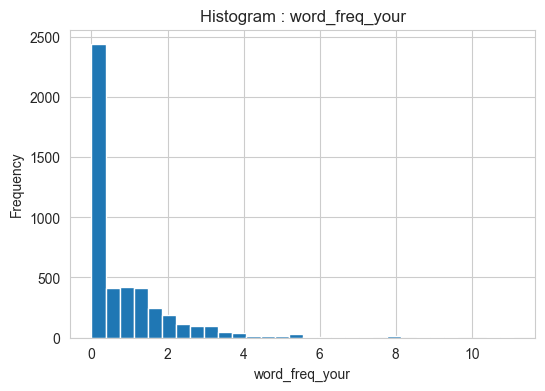

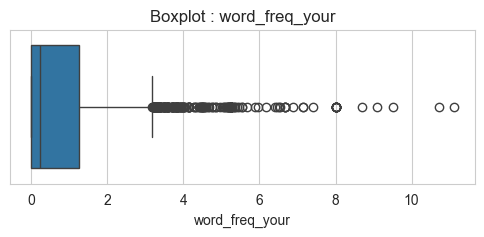

Outliers Detected : 229

--------------------------------------------------------------------------------
Column : word_freq_font
--------------------------------------------------------------------------------
Mean       : 0.121
Median     : 0.000
Std Dev    : 1.026
Variance   : 1.052
Skewness   : 9.975
Kurtosis   : 109.142


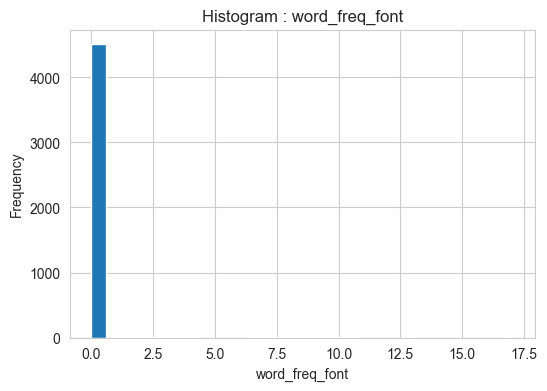

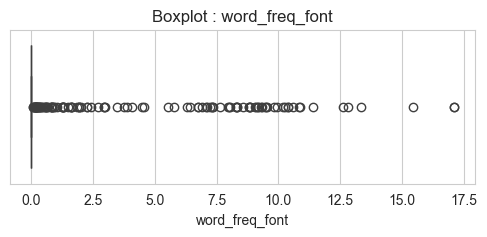

Outliers Detected : 117

--------------------------------------------------------------------------------
Column : word_freq_000
--------------------------------------------------------------------------------
Mean       : 0.102
Median     : 0.000
Std Dev    : 0.350
Variance   : 0.123
Skewness   : 5.714
Kurtosis   : 46.808


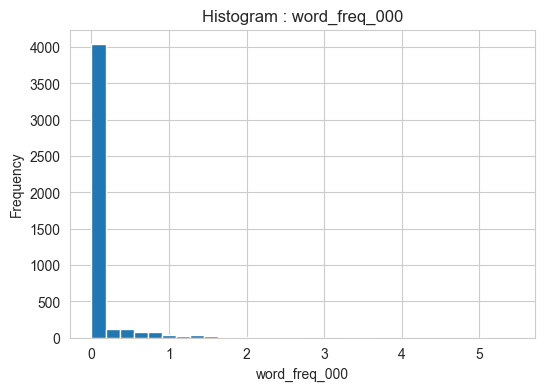

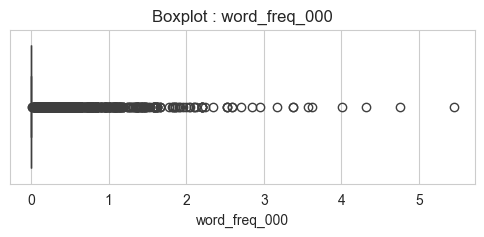

Outliers Detected : 679

--------------------------------------------------------------------------------
Column : word_freq_money
--------------------------------------------------------------------------------
Mean       : 0.094
Median     : 0.000
Std Dev    : 0.443
Variance   : 0.196
Skewness   : 14.687
Kurtosis   : 302.056


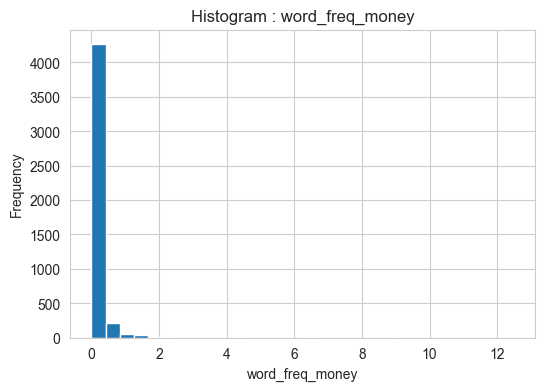

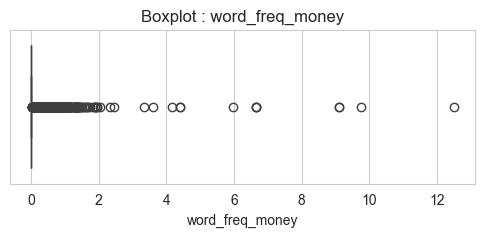

Outliers Detected : 735

--------------------------------------------------------------------------------
Column : word_freq_hp
--------------------------------------------------------------------------------
Mean       : 0.550
Median     : 0.000
Std Dev    : 1.671
Variance   : 2.793
Skewness   : 5.717
Kurtosis   : 43.604


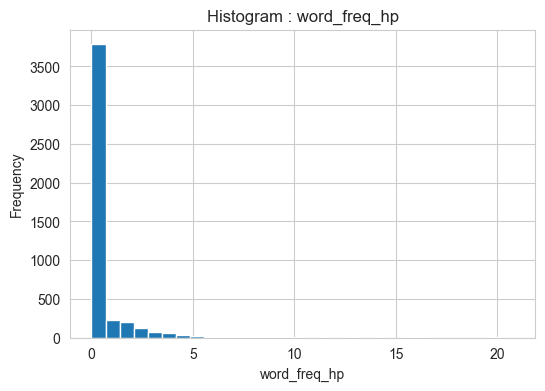

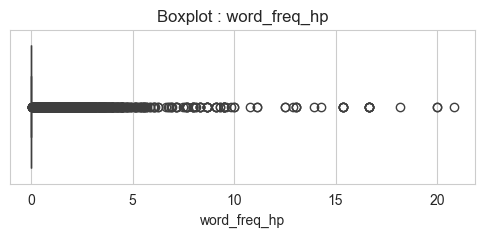

Outliers Detected : 1090

--------------------------------------------------------------------------------
Column : word_freq_hpl
--------------------------------------------------------------------------------
Mean       : 0.265
Median     : 0.000
Std Dev    : 0.887
Variance   : 0.787
Skewness   : 6.350
Kurtosis   : 63.900


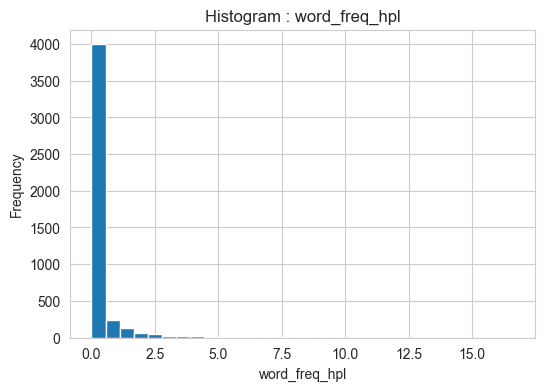

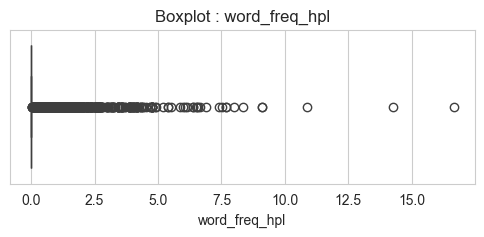

Outliers Detected : 811

--------------------------------------------------------------------------------
Column : word_freq_george
--------------------------------------------------------------------------------
Mean       : 0.767
Median     : 0.000
Std Dev    : 3.367
Variance   : 11.339
Skewness   : 5.744
Kurtosis   : 34.204


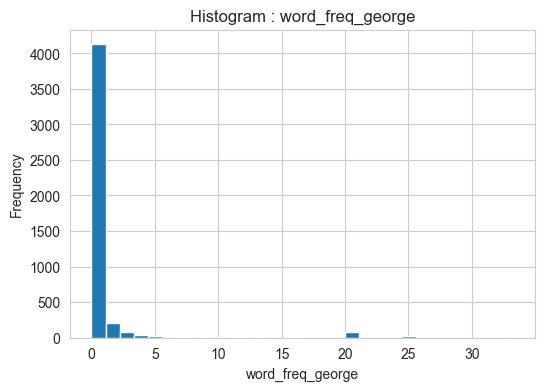

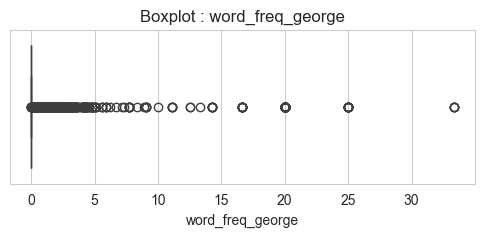

Outliers Detected : 780

--------------------------------------------------------------------------------
Column : word_freq_650
--------------------------------------------------------------------------------
Mean       : 0.125
Median     : 0.000
Std Dev    : 0.539
Variance   : 0.290
Skewness   : 6.607
Kurtosis   : 58.373


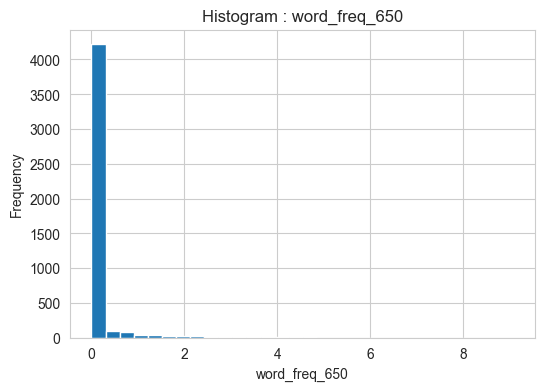

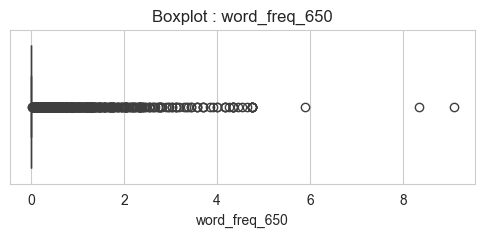

Outliers Detected : 463

--------------------------------------------------------------------------------
Column : word_freq_lab
--------------------------------------------------------------------------------
Mean       : 0.099
Median     : 0.000
Std Dev    : 0.593
Variance   : 0.352
Skewness   : 11.370
Kurtosis   : 175.248


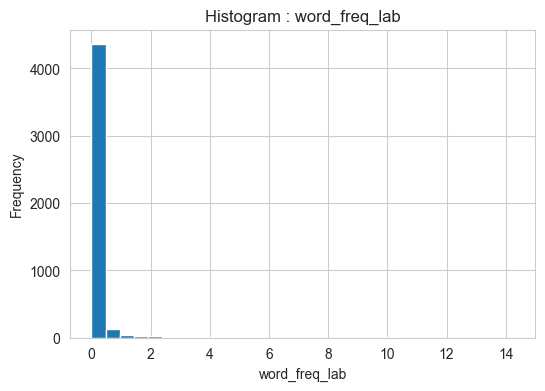

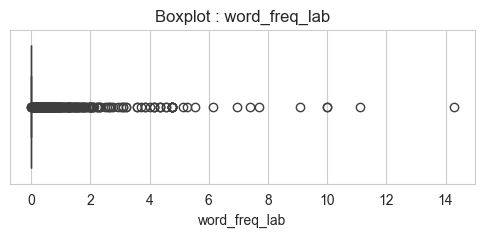

Outliers Detected : 372

--------------------------------------------------------------------------------
Column : word_freq_labs
--------------------------------------------------------------------------------
Mean       : 0.103
Median     : 0.000
Std Dev    : 0.457
Variance   : 0.209
Skewness   : 6.636
Kurtosis   : 52.007


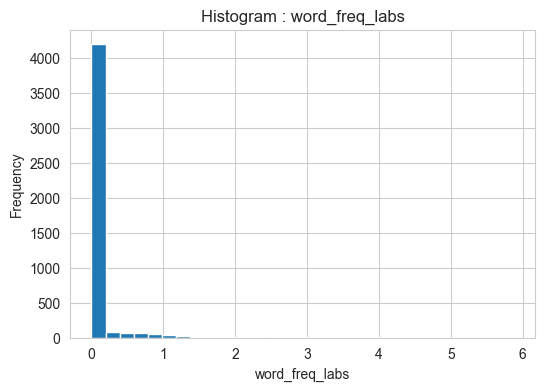

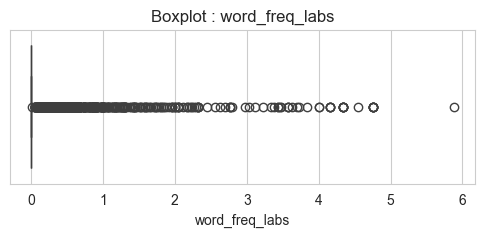

Outliers Detected : 469

--------------------------------------------------------------------------------
Column : word_freq_telnet
--------------------------------------------------------------------------------
Mean       : 0.065
Median     : 0.000
Std Dev    : 0.403
Variance   : 0.163
Skewness   : 12.669
Kurtosis   : 254.233


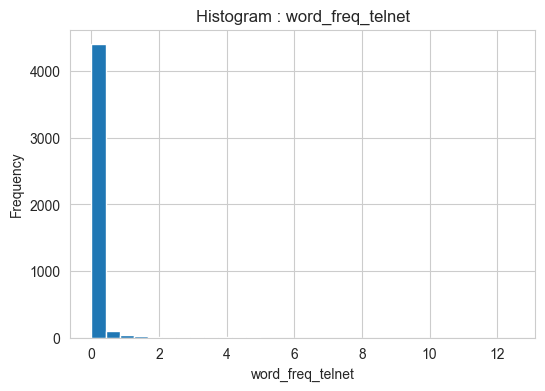

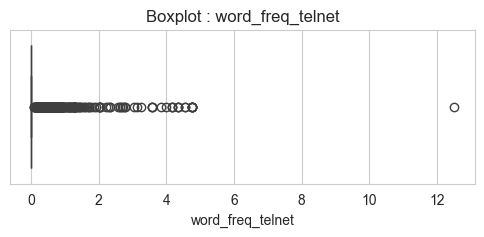

Outliers Detected : 293

--------------------------------------------------------------------------------
Column : word_freq_857
--------------------------------------------------------------------------------
Mean       : 0.047
Median     : 0.000
Std Dev    : 0.329
Variance   : 0.108
Skewness   : 10.549
Kurtosis   : 127.377


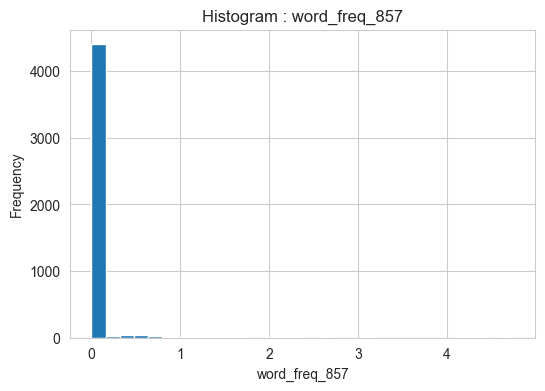

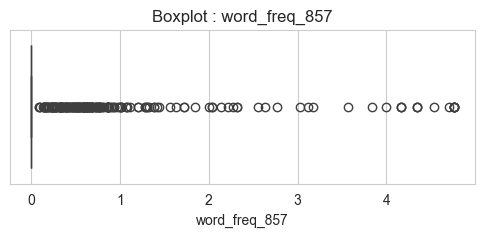

Outliers Detected : 205

--------------------------------------------------------------------------------
Column : word_freq_data
--------------------------------------------------------------------------------
Mean       : 0.097
Median     : 0.000
Std Dev    : 0.556
Variance   : 0.309
Skewness   : 13.190
Kurtosis   : 296.088


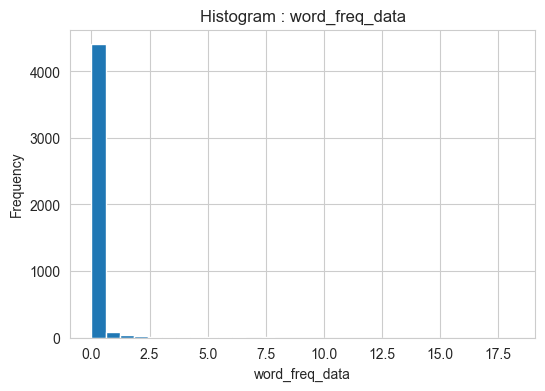

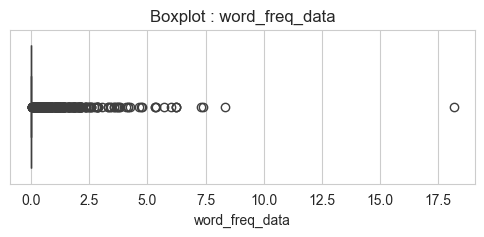

Outliers Detected : 405

--------------------------------------------------------------------------------
Column : word_freq_415
--------------------------------------------------------------------------------
Mean       : 0.048
Median     : 0.000
Std Dev    : 0.329
Variance   : 0.109
Skewness   : 10.475
Kurtosis   : 125.943


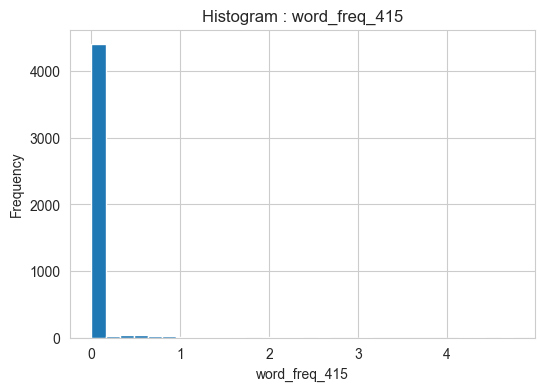

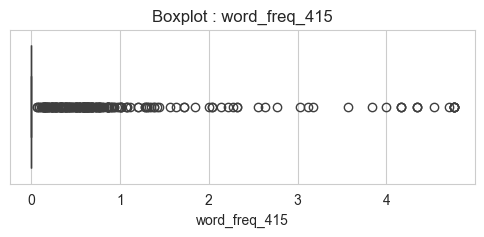

Outliers Detected : 215

--------------------------------------------------------------------------------
Column : word_freq_85
--------------------------------------------------------------------------------
Mean       : 0.105
Median     : 0.000
Std Dev    : 0.532
Variance   : 0.283
Skewness   : 15.231
Kurtosis   : 449.374


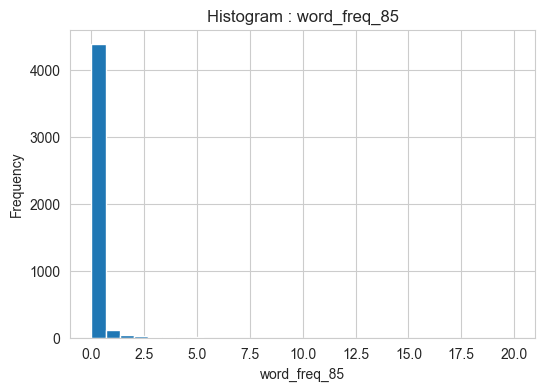

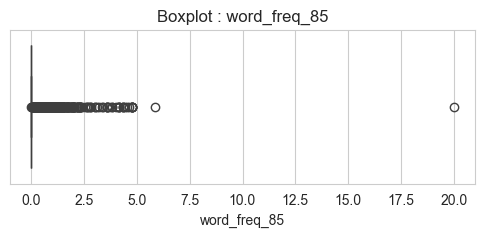

Outliers Detected : 485

--------------------------------------------------------------------------------
Column : word_freq_technology
--------------------------------------------------------------------------------
Mean       : 0.097
Median     : 0.000
Std Dev    : 0.403
Variance   : 0.162
Skewness   : 7.673
Kurtosis   : 81.207


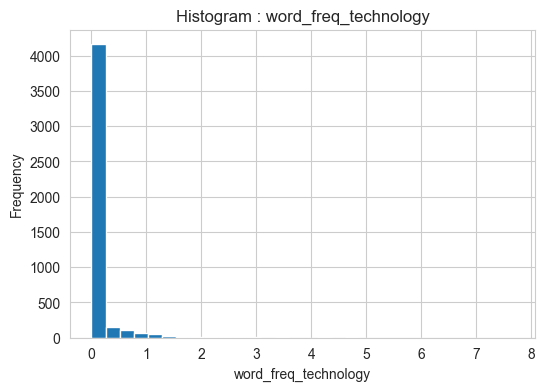

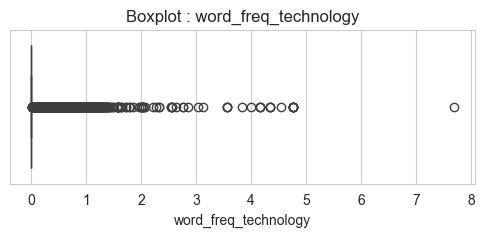

Outliers Detected : 599

--------------------------------------------------------------------------------
Column : word_freq_1999
--------------------------------------------------------------------------------
Mean       : 0.137
Median     : 0.000
Std Dev    : 0.423
Variance   : 0.179
Skewness   : 5.323
Kurtosis   : 42.621


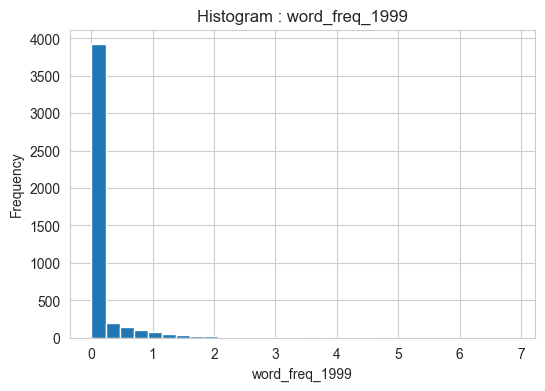

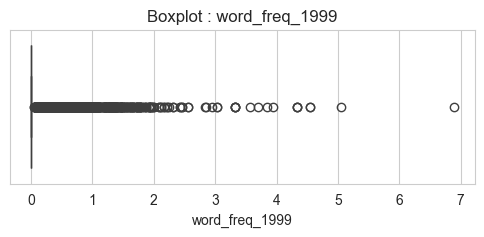

Outliers Detected : 829

--------------------------------------------------------------------------------
Column : word_freq_parts
--------------------------------------------------------------------------------
Mean       : 0.013
Median     : 0.000
Std Dev    : 0.221
Variance   : 0.049
Skewness   : 28.263
Kurtosis   : 912.046


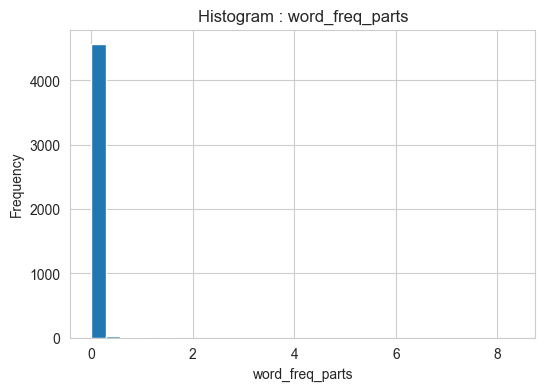

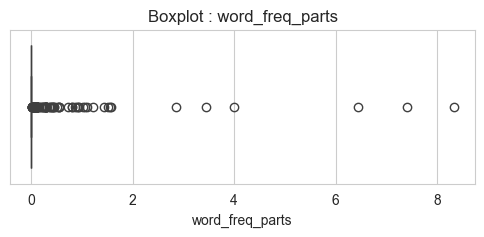

Outliers Detected : 83

--------------------------------------------------------------------------------
Column : word_freq_pm
--------------------------------------------------------------------------------
Mean       : 0.079
Median     : 0.000
Std Dev    : 0.435
Variance   : 0.189
Skewness   : 12.057
Kurtosis   : 215.718


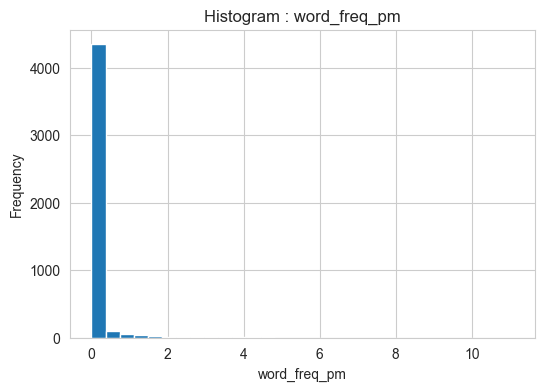

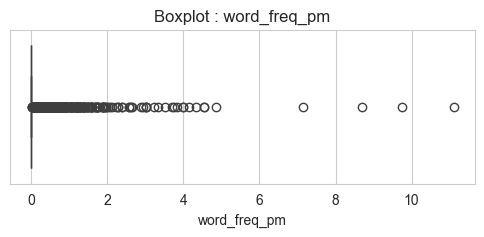

Outliers Detected : 384

--------------------------------------------------------------------------------
Column : word_freq_direct
--------------------------------------------------------------------------------
Mean       : 0.065
Median     : 0.000
Std Dev    : 0.350
Variance   : 0.122
Skewness   : 9.147
Kurtosis   : 99.387


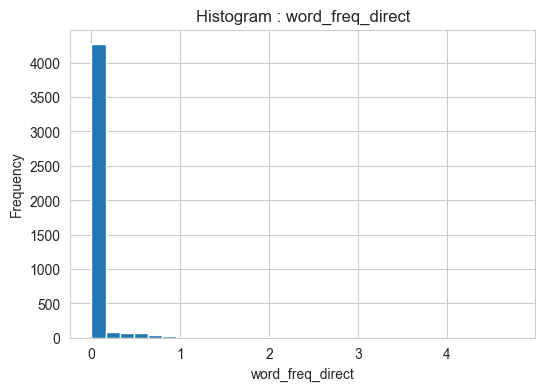

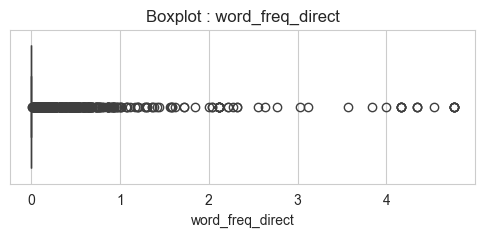

Outliers Detected : 453

--------------------------------------------------------------------------------
Column : word_freq_cs
--------------------------------------------------------------------------------
Mean       : 0.044
Median     : 0.000
Std Dev    : 0.361
Variance   : 0.130
Skewness   : 12.588
Kurtosis   : 193.619


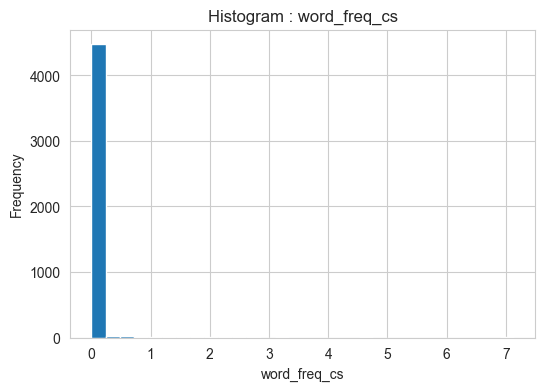

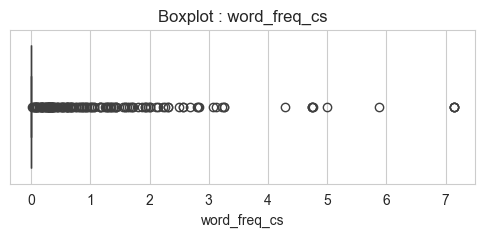

Outliers Detected : 148

--------------------------------------------------------------------------------
Column : word_freq_meeting
--------------------------------------------------------------------------------
Mean       : 0.132
Median     : 0.000
Std Dev    : 0.767
Variance   : 0.588
Skewness   : 9.456
Kurtosis   : 115.706


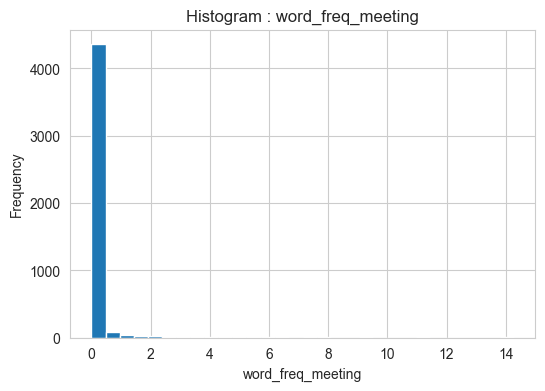

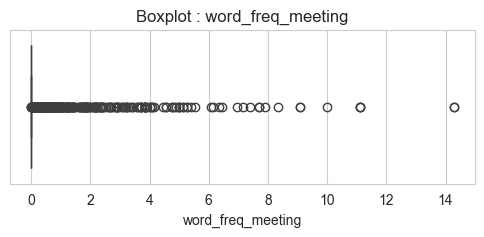

Outliers Detected : 341

--------------------------------------------------------------------------------
Column : word_freq_original
--------------------------------------------------------------------------------
Mean       : 0.046
Median     : 0.000
Std Dev    : 0.224
Variance   : 0.050
Skewness   : 7.629
Kurtosis   : 78.572


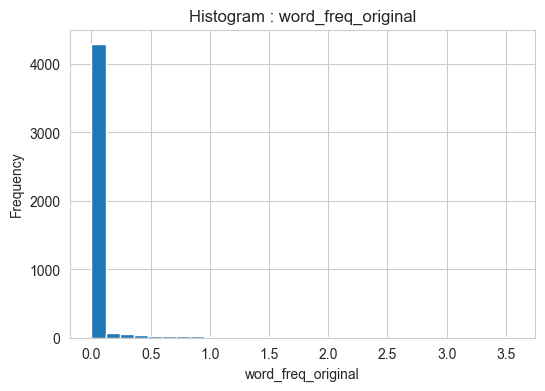

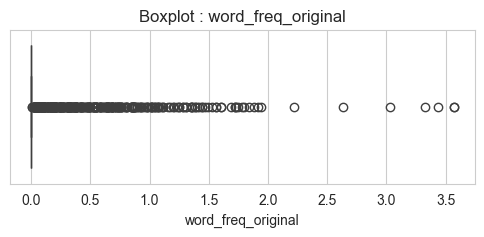

Outliers Detected : 375

--------------------------------------------------------------------------------
Column : word_freq_project
--------------------------------------------------------------------------------
Mean       : 0.079
Median     : 0.000
Std Dev    : 0.622
Variance   : 0.387
Skewness   : 18.772
Kurtosis   : 479.831


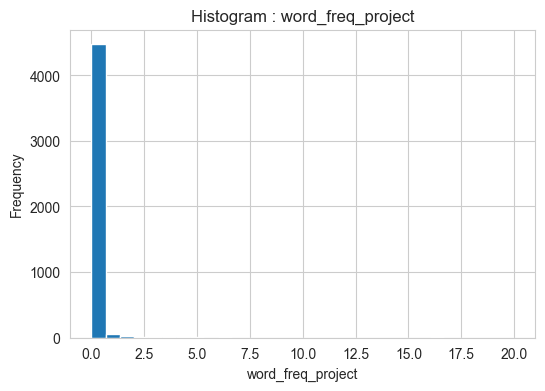

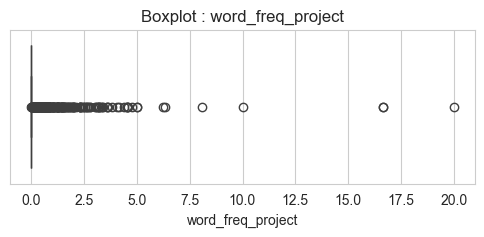

Outliers Detected : 327

--------------------------------------------------------------------------------
Column : word_freq_re
--------------------------------------------------------------------------------
Mean       : 0.301
Median     : 0.000
Std Dev    : 1.012
Variance   : 1.024
Skewness   : 9.146
Kurtosis   : 128.865


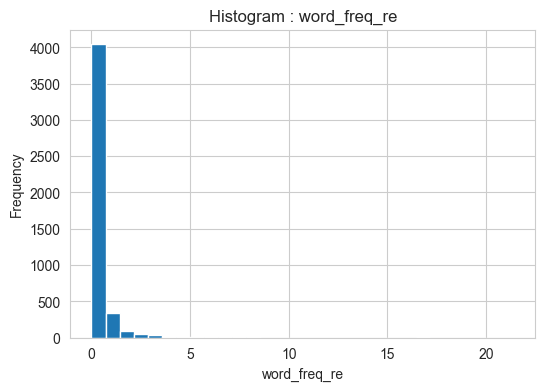

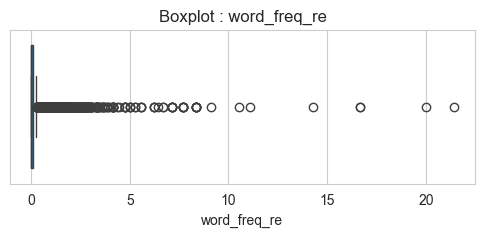

Outliers Detected : 1001

--------------------------------------------------------------------------------
Column : word_freq_edu
--------------------------------------------------------------------------------
Mean       : 0.180
Median     : 0.000
Std Dev    : 0.911
Variance   : 0.830
Skewness   : 10.123
Kurtosis   : 150.900


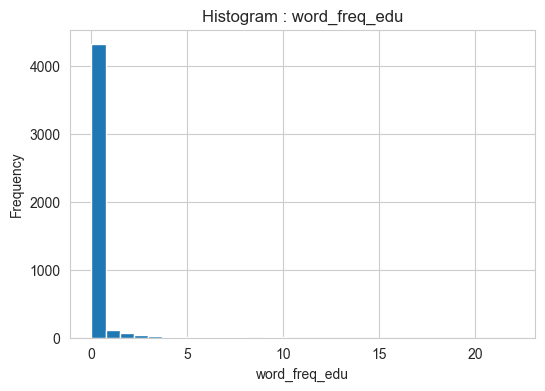

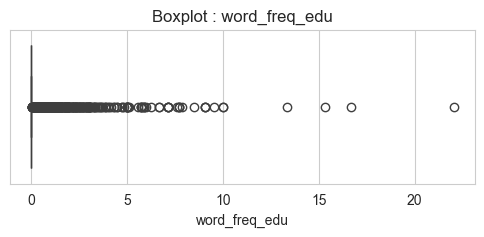

Outliers Detected : 517

--------------------------------------------------------------------------------
Column : word_freq_table
--------------------------------------------------------------------------------
Mean       : 0.005
Median     : 0.000
Std Dev    : 0.076
Variance   : 0.006
Skewness   : 19.868
Kurtosis   : 459.433


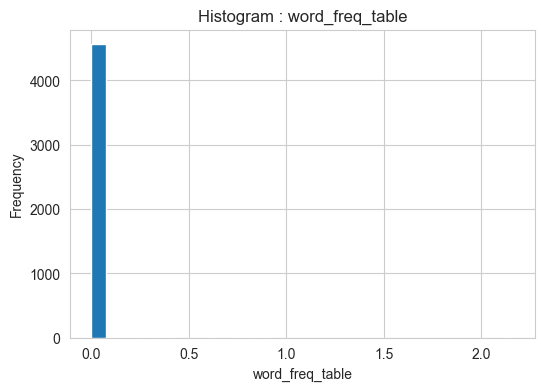

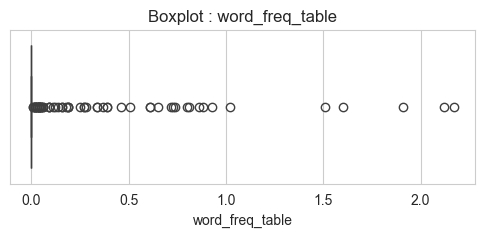

Outliers Detected : 63

--------------------------------------------------------------------------------
Column : word_freq_conference
--------------------------------------------------------------------------------
Mean       : 0.032
Median     : 0.000
Std Dev    : 0.286
Variance   : 0.082
Skewness   : 19.720
Kurtosis   : 537.493


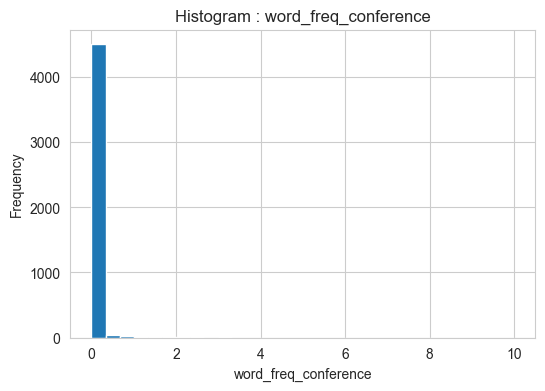

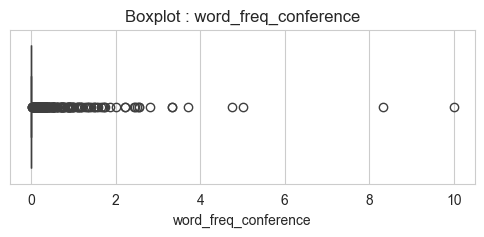

Outliers Detected : 203

--------------------------------------------------------------------------------
Column : char_freq_%3B
--------------------------------------------------------------------------------
Mean       : 0.039
Median     : 0.000
Std Dev    : 0.243
Variance   : 0.059
Skewness   : 13.709
Kurtosis   : 213.068


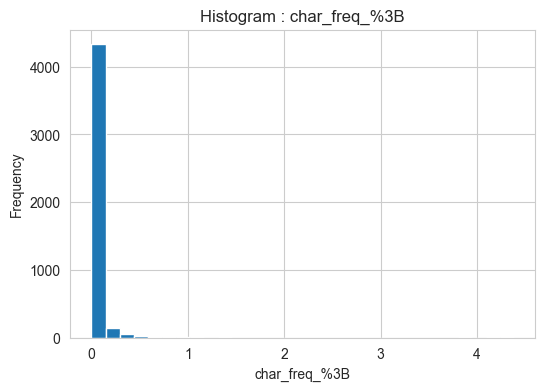

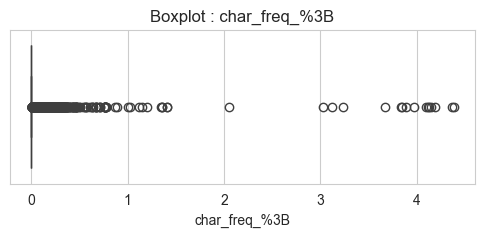

Outliers Detected : 790

--------------------------------------------------------------------------------
Column : char_freq_%28
--------------------------------------------------------------------------------
Mean       : 0.139
Median     : 0.065
Std Dev    : 0.270
Variance   : 0.073
Skewness   : 13.584
Kurtosis   : 393.415


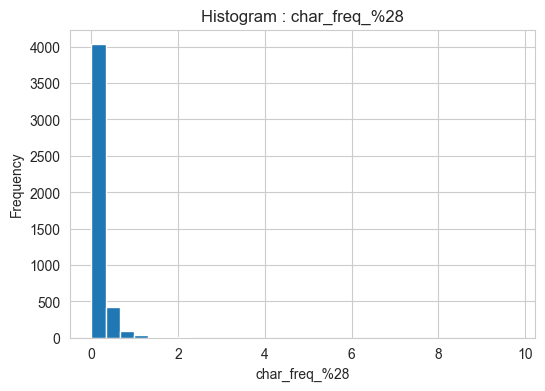

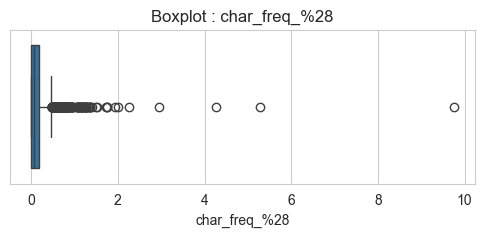

Outliers Detected : 296

--------------------------------------------------------------------------------
Column : char_freq_%5B
--------------------------------------------------------------------------------
Mean       : 0.017
Median     : 0.000
Std Dev    : 0.109
Variance   : 0.012
Skewness   : 21.084
Kurtosis   : 618.476


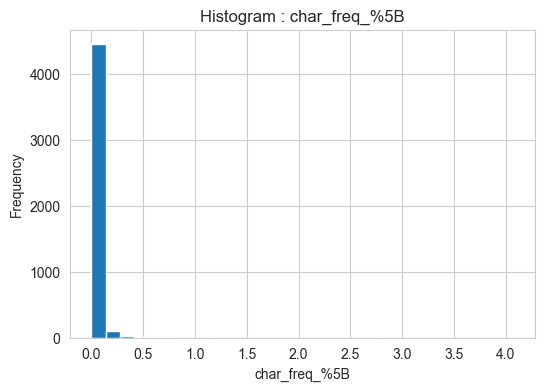

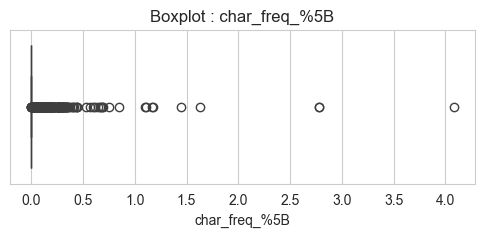

Outliers Detected : 529

--------------------------------------------------------------------------------
Column : char_freq_%21
--------------------------------------------------------------------------------
Mean       : 0.269
Median     : 0.000
Std Dev    : 0.816
Variance   : 0.665
Skewness   : 18.658
Kurtosis   : 607.456


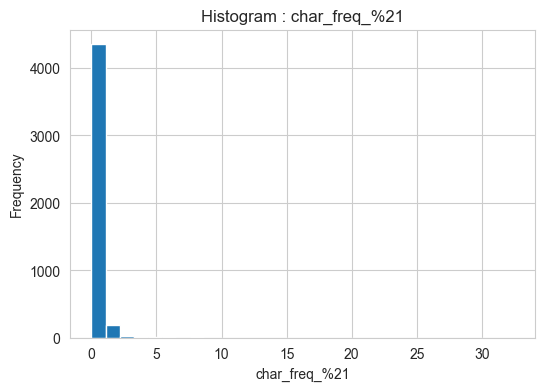

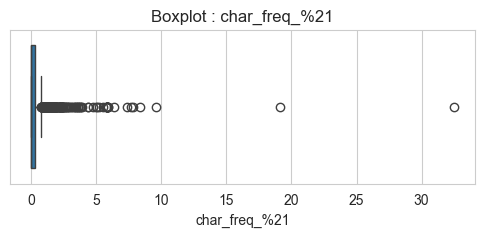

Outliers Detected : 411

--------------------------------------------------------------------------------
Column : char_freq_%24
--------------------------------------------------------------------------------
Mean       : 0.076
Median     : 0.000
Std Dev    : 0.246
Variance   : 0.060
Skewness   : 11.163
Kurtosis   : 199.954


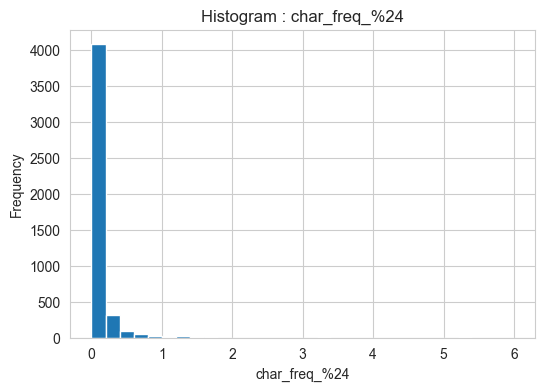

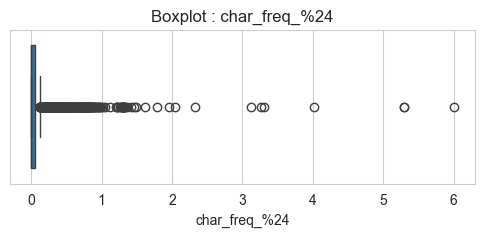

Outliers Detected : 811

--------------------------------------------------------------------------------
Column : char_freq_%23
--------------------------------------------------------------------------------
Mean       : 0.044
Median     : 0.000
Std Dev    : 0.429
Variance   : 0.184
Skewness   : 31.062
Kurtosis   : 1218.494


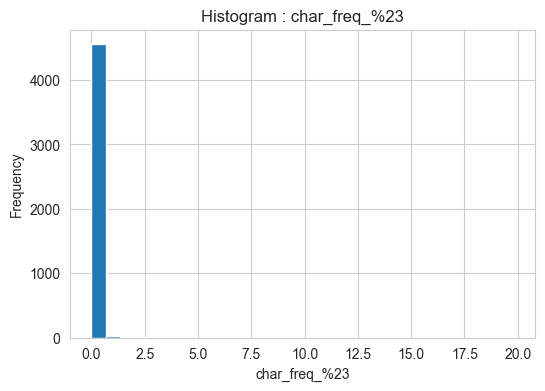

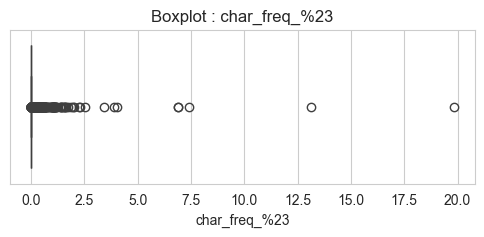

Outliers Detected : 750

--------------------------------------------------------------------------------
Column : capital_run_length_average
--------------------------------------------------------------------------------
Mean       : 5.192
Median     : 2.276
Std Dev    : 31.729
Variance   : 1006.758
Skewness   : 23.762
Kurtosis   : 670.369


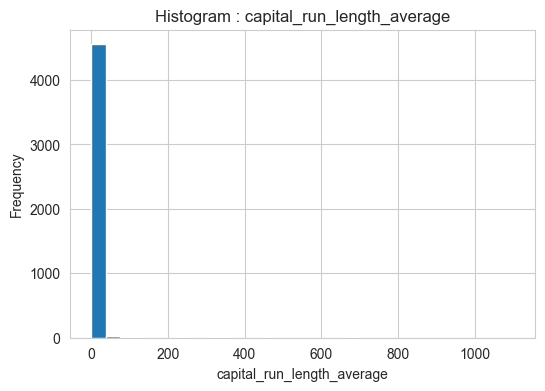

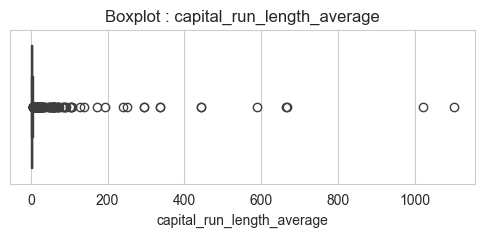

Outliers Detected : 363

--------------------------------------------------------------------------------
Column : capital_run_length_longest
--------------------------------------------------------------------------------
Mean       : 52.173
Median     : 15.000
Std Dev    : 194.891
Variance   : 37982.623
Skewness   : 30.765
Kurtosis   : 1480.642


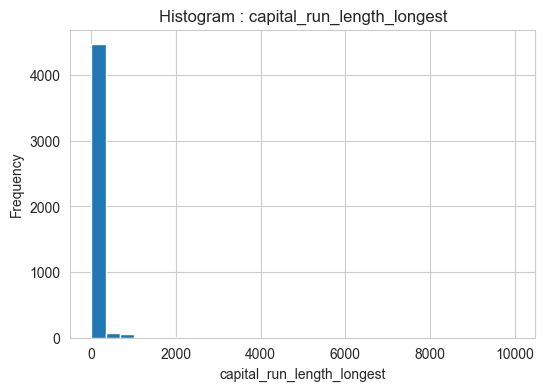

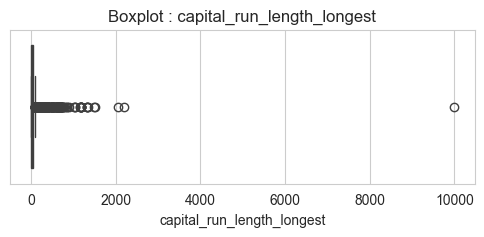

Outliers Detected : 463

--------------------------------------------------------------------------------
Column : capital_run_length_total
--------------------------------------------------------------------------------
Mean       : 283.289
Median     : 95.000
Std Dev    : 606.348
Variance   : 367657.716
Skewness   : 8.710
Kurtosis   : 145.830


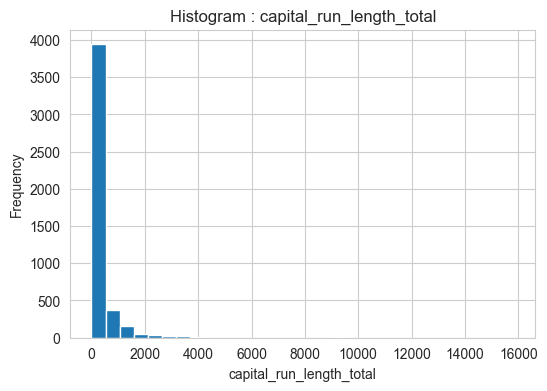

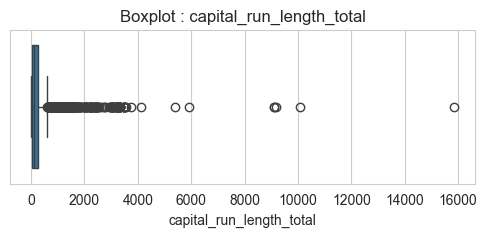

Outliers Detected : 550

--------------------------------------------------------------------------------
Column : class
--------------------------------------------------------------------------------
Mean       : 0.394
Median     : 0.000
Std Dev    : 0.489
Variance   : 0.239
Skewness   : 0.434
Kurtosis   : -1.813


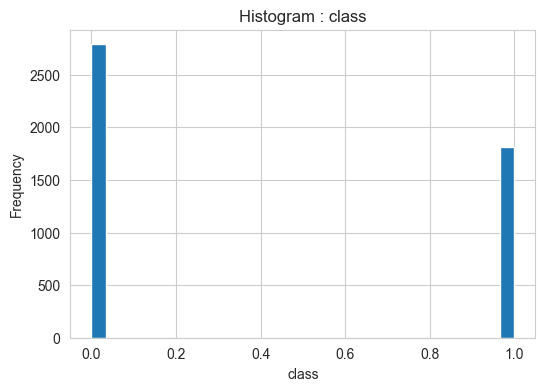

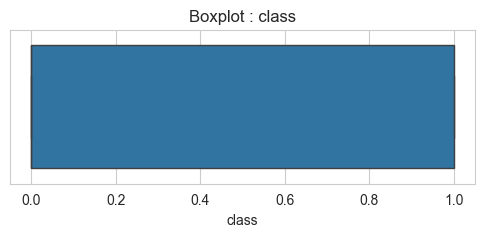

Outliers Detected : 0


CATEGORICAL FEATURE ANALYSIS


CORRELATION ANALYSIS


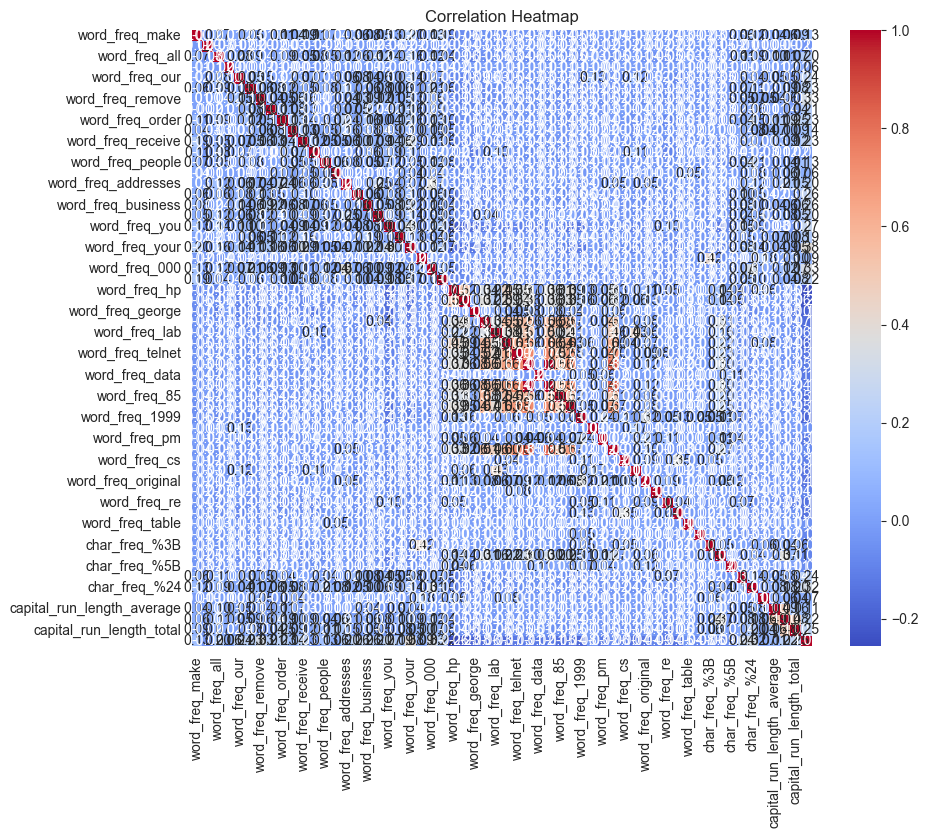


Highly Correlated Feature Pairs
word_freq_857, word_freq_415 = 0.9960660509313944
word_freq_857, word_freq_direct = 0.848020708618814
word_freq_415, word_freq_direct = 0.8453591164400025


TARGET ANALYSIS
class
0    2788
1    1813
Name: count, dtype: int64


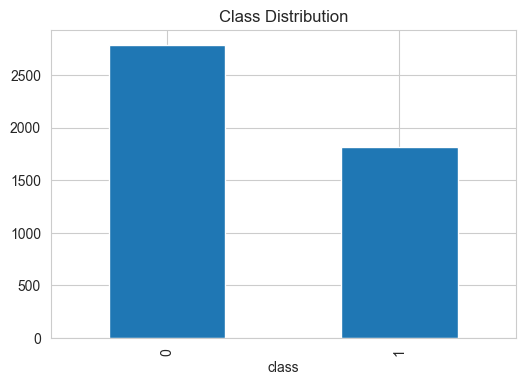



FINAL EDA SUMMARY
Rows                     : 4601
Columns                  : 58
Numerical Columns        : 58
Categorical Columns      : 0
Duplicate Rows           : 391
Columns with Missing     : 0
Highly Correlated Pairs  : 3

EDA Completed Successfully.


In [15]:
tabular_eda(df, "classification", "class")

## 5. Data Preprocessing

In [16]:
print("Shape before de-duplication:", df.shape)
df = df.drop_duplicates()
print("Duplicate rows remaining:", df.duplicated().sum())
print("Shape after de-duplication:", df.shape)

Shape before de-duplication: (4601, 58)
Duplicate rows remaining: 0
Shape after de-duplication: (4210, 58)


## 6. Feature and Target Split

In [17]:
X = df.drop("class", axis=1)
y = df["class"]

print("Features shape:", X.shape)
print("Target distribution:\n", y.value_counts(normalize=True))

Features shape: (4210, 57)
Target distribution:
 class
0    0.601188
1    0.398812
Name: proportion, dtype: float64


## 7. Train-Test Split and Feature Scaling
An 80/20 split is used, keeping the same spam-to-ham ratio in both sets (`stratify=y`). `StandardScaler` is fit only on the training data and then applied to both sets, so the test data stays unseen during scaling.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

Train shape: (3368, 57)  Test shape: (842, 57)


In [19]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 8. Baseline Logistic Regression


In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

start_time = time.perf_counter()
log_reg_baseline = LogisticRegression()
log_reg_baseline.fit(X_train_scaled, y_train)
training_time_baseline = time.perf_counter() - start_time

y_pred = log_reg_baseline.predict(X_test_scaled)

accuracy_baseline = accuracy_score(y_test, y_pred)
precision_baseline = precision_score(y_test, y_pred)
recall_baseline = recall_score(y_test, y_pred)
f1_baseline = f1_score(y_test, y_pred)

print(f"Accuracy      : {accuracy_baseline:.4f}")
print(f"Precision     : {precision_baseline:.4f}")
print(f"Recall        : {recall_baseline:.4f}")
print(f"F1 Score      : {f1_baseline:.4f}")
print(f"Training Time : {training_time_baseline:.4f} s")

Accuracy      : 0.9347
Precision     : 0.9297
Recall        : 0.9048
F1 Score      : 0.9170
Training Time : 0.0166 s


## 9. Tuning of  Logistic Regression

`GridSearchCV` is used to try every combination of the settings below, with 5-fold cross validation, and keep the combination with the best accuracy:
- `penalty`: L1 (Lasso-style, can drop some features entirely) or L2 (Ridge-style, keeps all features but shrinks them)
- `C`: how strong the regularization is -- a **small C** means **strong** regularization (simpler model), a **large C** means **weak** regularization (more complex model)
- `solver`: the optimization method used to fit the model (`liblinear` and `saga` both support L1 and L2 here)

In [21]:
param_grid_lr = {
    'penalty': ['l1', 'l2'],
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'saga']
}

In [22]:
from sklearn.model_selection import GridSearchCV

start_time_grid_lr = time.perf_counter()

grid_lr = GridSearchCV(
    estimator=LogisticRegression(max_iter=10000),
    param_grid=param_grid_lr,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

grid_lr.fit(X_train_scaled, y_train)
training_time_grid_lr = time.perf_counter() - start_time_grid_lr

print("Best Parameters:", grid_lr.best_params_)
print("Best CV Accuracy:", grid_lr.best_score_)

Best Parameters: {'C': 1, 'penalty': 'l1', 'solver': 'liblinear'}
Best CV Accuracy: 0.9242891345276256


### Evaluation of Tuned Logistic Regression Model

Accuracy : 0.9370546318289786
Precision: 0.9300911854103343
Recall   : 0.9107142857142857
F1 Score : 0.9203007518796993
Training Time : 39.90814209997188


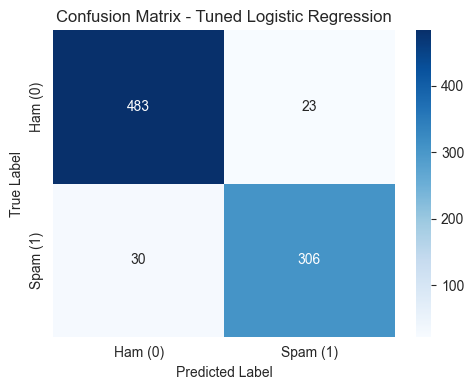

In [23]:
best_lr_model = grid_lr.best_estimator_
y_pred_lr = best_lr_model.predict(X_test_scaled)

accuracy_lr_tuned = accuracy_score(y_test, y_pred_lr)
precision_lr_tuned = precision_score(y_test, y_pred_lr)
recall_lr_tuned = recall_score(y_test, y_pred_lr)
f1_lr_tuned = f1_score(y_test, y_pred_lr)

print("Accuracy :", accuracy_lr_tuned)
print("Precision:", precision_lr_tuned)
print("Recall   :", recall_lr_tuned)
print("F1 Score :", f1_lr_tuned)
print("Training Time :", training_time_grid_lr)

# Visualization: Confusion Matrix for Logistic Regression
from sklearn.metrics import confusion_matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=ax, xticklabels=['Ham (0)', 'Spam (1)'], yticklabels=['Ham (0)', 'Spam (1)'])
ax.set_title('Confusion Matrix - Tuned Logistic Regression')
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
plt.tight_layout()
plt.show()


### 5-Fold Cross Validation -- Logistic Regression

In [24]:
from sklearn.model_selection import cross_val_score

lr_cv_model = LogisticRegression(max_iter=10000, **grid_lr.best_params_)

lr_cv_scores = cross_val_score(
    lr_cv_model,
    X_train_scaled,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("Cross-Validation Accuracy Scores:", lr_cv_scores)
print("Mean Accuracy:", lr_cv_scores.mean())
print("Standard Deviation:", lr_cv_scores.std())

Cross-Validation Accuracy Scores: [0.91691395 0.92581602 0.92433234 0.92124814 0.93313522]
Mean Accuracy: 0.9242891345276256
Standard Deviation: 0.0053707994612477395


## 10. Support Vector Machine (SVM)
A Support Vector Machine looks for the boundary line (or curve) that separates spam from ham with the widest possible gap between the two classes.

In [25]:
from sklearn.svm import SVC

### 10a. Baseline SVM
Trained first with all default settings (which uses the RBF kernel), as a starting point.

In [26]:
start_time = time.perf_counter()

baseline_svm = SVC()
baseline_svm.fit(X_train_scaled, y_train)

training_time_svm_baseline = time.perf_counter() - start_time

y_pred = baseline_svm.predict(X_test_scaled)

print("Baseline SVM")
print(f"Accuracy      : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision     : {precision_score(y_test, y_pred):.4f}")
print(f"Recall        : {recall_score(y_test, y_pred):.4f}")
print(f"F1 Score      : {f1_score(y_test, y_pred):.4f}")
print(f"Training Time : {training_time_svm_baseline:.4f} s")

Baseline SVM
Accuracy      : 0.9323
Precision     : 0.9319
Recall        : 0.8958
F1 Score      : 0.9135
Training Time : 0.2576 s


### 10b. Train SVM with Different Kernels

Each kernel decides the shape of the boundary SVM is allowed to draw:
- **Linear** -- a straight boundary line, works when the classes are already roughly separable in a straight-line way.
- **Polynomial** -- a curved boundary that can bend to follow polynomial-shaped patterns.
- **RBF** -- a flexible, curved boundary that can wrap around more complicated shapes.
- **Sigmoid** -- shaped like the activation function used in neural networks.

The results for each kernel are collected into a table so they can be compared side by side afterwards.

In [27]:
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
kernel_results = []

for kernel in kernels:
    print("=" * 60)
    print(f"Kernel : {kernel}")

    model = SVC(kernel=kernel)

    start = time.perf_counter()
    model.fit(X_train_scaled, y_train)
    kernel_train_time = time.perf_counter() - start

    y_pred = model.predict(X_test_scaled)

    kernel_accuracy = accuracy_score(y_test, y_pred)
    kernel_f1 = f1_score(y_test, y_pred)

    print(f"Accuracy      : {kernel_accuracy:.4f}")
    print(f"Precision     : {precision_score(y_test, y_pred):.4f}")
    print(f"Recall        : {recall_score(y_test, y_pred):.4f}")
    print(f"F1 Score      : {kernel_f1:.4f}")
    print(f"Training Time : {kernel_train_time:.4f} s")

    kernel_results.append({
        "Kernel": kernel,
        "Accuracy": kernel_accuracy,
        "F1 Score": kernel_f1,
        "Training Time (s)": kernel_train_time
    })

Kernel : linear
Accuracy      : 0.9359
Precision     : 0.9273
Recall        : 0.9107
F1 Score      : 0.9189
Training Time : 0.2734 s
Kernel : poly
Accuracy      : 0.7660
Precision     : 0.9484
Recall        : 0.4375
F1 Score      : 0.5988
Training Time : 0.2478 s
Kernel : rbf
Accuracy      : 0.9323
Precision     : 0.9319
Recall        : 0.8958
F1 Score      : 0.9135
Training Time : 0.1499 s
Kernel : sigmoid
Accuracy      : 0.8967
Precision     : 0.8879
Recall        : 0.8482
F1 Score      : 0.8676
Training Time : 0.1341 s


### Table -- SVM Kernel-wise Performance

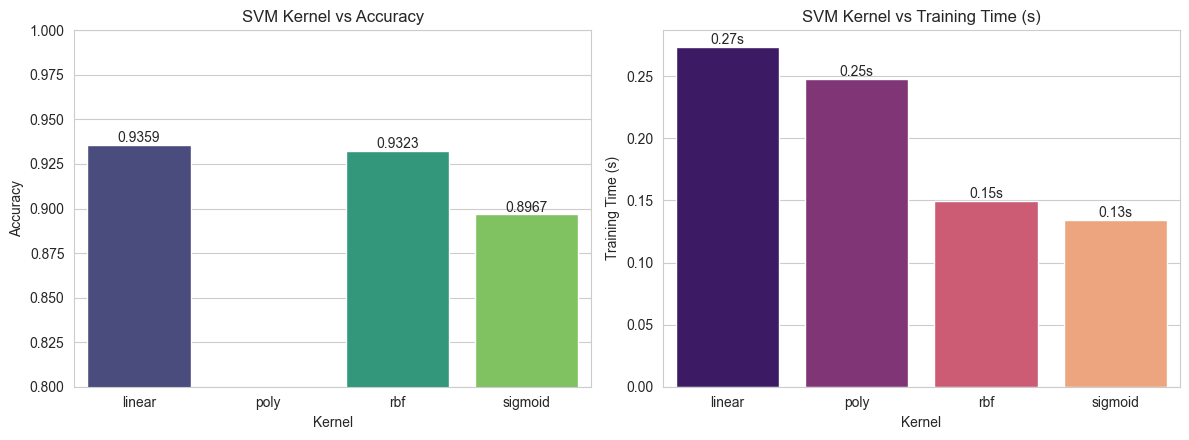

,Accuracy,F1 Score,Training Time (s)
Kernel,,,
linear,0.935867,0.918919,0.273359
poly,0.766033,0.598778,0.247848
rbf,0.932304,0.913505,0.149884
sigmoid,0.896675,0.867580,0.134122


In [28]:
svm_kernel_table = pd.DataFrame(kernel_results).set_index("Kernel")

# Visualization: SVM Kernel Performance Comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=pd.DataFrame(kernel_results), x='Kernel', y='Accuracy', palette='viridis', ax=axes[0])
axes[0].set_title('SVM Kernel vs Accuracy')
axes[0].set_ylim(0.8, 1.0)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points')

sns.barplot(data=pd.DataFrame(kernel_results), x='Kernel', y='Training Time (s)', palette='magma', ax=axes[1])
axes[1].set_title('SVM Kernel vs Training Time (s)')
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.2f}s", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

svm_kernel_table


## 11. Tune SVM

`GridSearchCV` is used again, this time over the SVM settings:
- `kernel`: which boundary shape to use (tried together with the other settings below)
- `C`: controls the margin width -- a **small C** allows a **wider** margin (simpler, more mistakes allowed), a **large C** forces a **narrower** margin (fits the training data more tightly)
- `gamma`: controls how far the influence of a single training point reaches -- only relevant for the non-linear kernels

In [29]:
param_grid_svm = {
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1]
}

In [30]:
start_time_grid_svm = time.perf_counter()

grid_svm = GridSearchCV(
    estimator=SVC(),
    param_grid=param_grid_svm,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

grid_svm.fit(X_train_scaled, y_train)
training_time_grid_svm = time.perf_counter() - start_time_grid_svm

print("Best Parameters :", grid_svm.best_params_)
print("Best CV Accuracy :", grid_svm.best_score_)

Best Parameters : {'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}
Best CV Accuracy : 0.9284469645195568


### Evaluation of Tuned SVM Model

Tuned SVM
Accuracy      : 0.9418
Precision     : 0.9309
Recall        : 0.9226
F1 Score      : 0.9268
Training Time : 139.2039 s


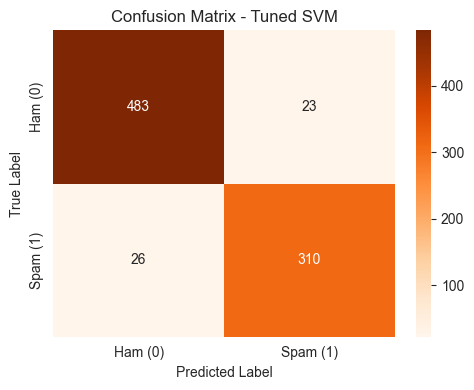

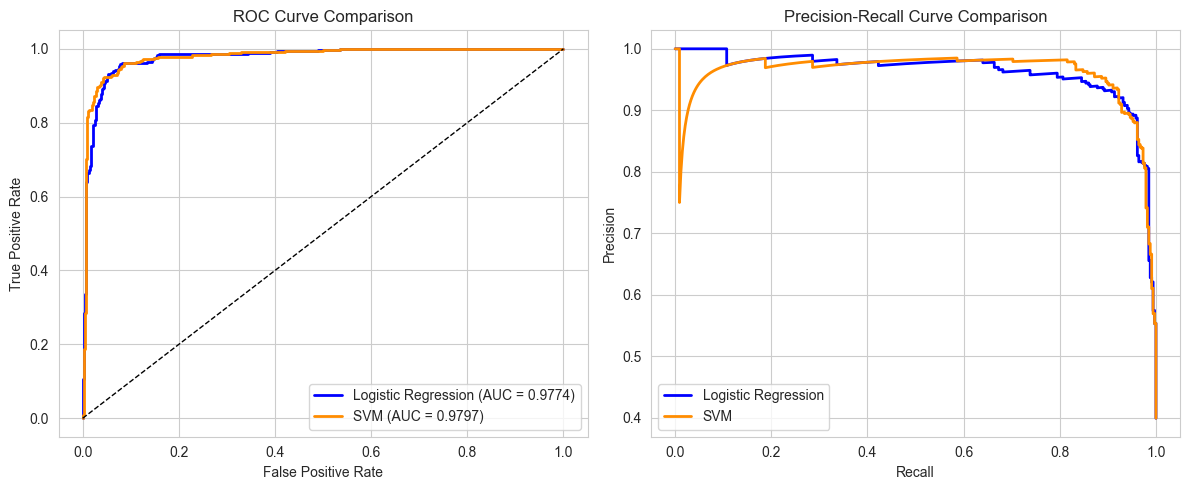

In [31]:
best_svm_model = grid_svm.best_estimator_
y_pred_svm = best_svm_model.predict(X_test_scaled)

accuracy_svm_tuned = accuracy_score(y_test, y_pred_svm)
precision_svm_tuned = precision_score(y_test, y_pred_svm)
recall_svm_tuned = recall_score(y_test, y_pred_svm)
f1_svm_tuned = f1_score(y_test, y_pred_svm)

print("Tuned SVM")
print(f"Accuracy      : {accuracy_svm_tuned:.4f}")
print(f"Precision     : {precision_svm_tuned:.4f}")
print(f"Recall        : {recall_svm_tuned:.4f}")
print(f"F1 Score      : {f1_svm_tuned:.4f}")
print(f"Training Time : {training_time_grid_svm:.4f} s")

# Visualization: Confusion Matrix for Tuned SVM
from sklearn.metrics import confusion_matrix, roc_curve, auc, precision_recall_curve
cm_svm = confusion_matrix(y_test, y_pred_svm)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Oranges', ax=ax, xticklabels=['Ham (0)', 'Spam (1)'], yticklabels=['Ham (0)', 'Spam (1)'])
ax.set_title('Confusion Matrix - Tuned SVM')
ax.set_xlabel('Predicted Label')
ax.set_ylabel('True Label')
plt.tight_layout()
plt.show()

# Visualization: ROC Curve and Precision-Recall Curve Comparison
y_prob_lr = best_lr_model.predict_proba(X_test_scaled)[:, 1]
if hasattr(best_svm_model, "decision_function"):
    y_score_svm = best_svm_model.decision_function(X_test_scaled)
else:
    y_score_svm = best_svm_model.predict_proba(X_test_scaled)[:, 1]

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
auc_lr = auc(fpr_lr, tpr_lr)

fpr_svm, tpr_svm, _ = roc_curve(y_test, y_score_svm)
auc_svm = auc(fpr_svm, tpr_svm)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# ROC Curve
axes[0].plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.4f})', color='blue', lw=2)
axes[0].plot(fpr_svm, tpr_svm, label=f'SVM (AUC = {auc_svm:.4f})', color='darkorange', lw=2)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curve Comparison')
axes[0].legend(loc='lower right')
axes[0].grid(True)

# Precision-Recall Curve
prec_lr, rec_lr, _ = precision_recall_curve(y_test, y_prob_lr)
prec_svm, rec_svm, _ = precision_recall_curve(y_test, y_score_svm)

axes[1].plot(rec_lr, prec_lr, label='Logistic Regression', color='blue', lw=2)
axes[1].plot(rec_svm, prec_svm, label='SVM', color='darkorange', lw=2)
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve Comparison')
axes[1].legend(loc='lower left')
axes[1].grid(True)

plt.tight_layout()
plt.show()


### 5-Fold Cross Validation -- SVM

In [32]:
svm_cv_scores = cross_val_score(
    best_svm_model,
    X_train_scaled,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("Cross Validation Scores:", svm_cv_scores)
print("Mean Accuracy :", svm_cv_scores.mean())
print("Std Deviation :", svm_cv_scores.std())

Cross Validation Scores: [0.9272997  0.92878338 0.91988131 0.92867756 0.93759287]
Mean Accuracy : 0.9284469645195568
Std Deviation : 0.005630286306406651


## 12. Hyperparameter Tuning Results


In [33]:
tuning_results = pd.DataFrame({
    "Model": ["Logistic Regression", "SVM"],
    "Search Method": ["Grid Search", "Grid Search"],
    "Best Parameters": [grid_lr.best_params_, grid_svm.best_params_],
    "Best CV Accuracy": [grid_lr.best_score_, grid_svm.best_score_],
})
tuning_results

,Model,Search Method,Best Parameters,Best CV Accuracy
0,Logistic Regression,Grid Search,"{'C': 1, 'penalty': 'l1', 'solver': 'liblinear'}",0.924289
1,SVM,Grid Search,"{'C': 10, 'gamma': 0.01, 'kernel': 'rbf'}",0.928447


## 13. Logistic Regression Performance

In [34]:
logistic_regression_performance = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score", "Training Time (s)"],
    "Value": [accuracy_lr_tuned, precision_lr_tuned, recall_lr_tuned, f1_lr_tuned, training_time_grid_lr],
})
logistic_regression_performance

,Metric,Value
0,Accuracy,0.937055
1,Precision,0.930091
2,Recall,0.910714
3,F1 Score,0.920301
4,Training Time (s),39.908142


## 14. K-Fold Cross-Validation Results (K = 5)


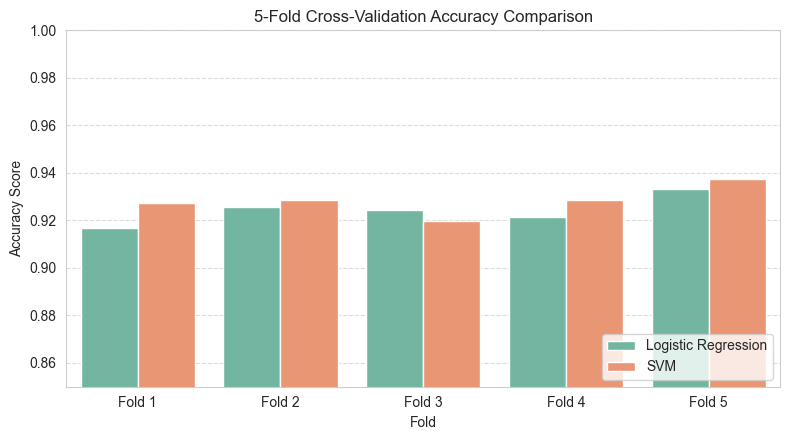

,Fold,Logistic Regression,SVM
0,1,0.916914,0.927300
1,2,0.925816,0.928783
2,3,0.924332,0.919881
3,4,0.921248,0.928678
4,5,0.933135,0.937593
5,Average,0.924289,0.928447


In [35]:
cv_fold_table = pd.DataFrame({
    "Fold": [1, 2, 3, 4, 5],
    "Logistic Regression": lr_cv_scores,
    "SVM": svm_cv_scores,
})
average_row = pd.DataFrame({
    "Fold": ["Average"],
    "Logistic Regression": [lr_cv_scores.mean()],
    "SVM": [svm_cv_scores.mean()],
})
cv_fold_table = pd.concat([cv_fold_table, average_row], ignore_index=True)

# Visualization: 5-Fold Cross Validation Accuracy Plot
folds_df = pd.DataFrame({
    "Fold": [f"Fold {i}" for i in range(1, 6)],
    "Logistic Regression": lr_cv_scores,
    "SVM": svm_cv_scores
})
folds_melted = folds_df.melt(id_vars="Fold", var_name="Model", value_name="CV Accuracy")

plt.figure(figsize=(8, 4.5))
sns.barplot(data=folds_melted, x="Fold", y="CV Accuracy", hue="Model", palette="Set2")
plt.ylim(0.85, 1.0)
plt.title("5-Fold Cross-Validation Accuracy Comparison")
plt.ylabel("Accuracy Score")
plt.legend(loc="lower right")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

cv_fold_table


## 15. Comparative Analysis


In [36]:
best_lr_accuracy = accuracy_lr_tuned
best_svm_accuracy = accuracy_svm_tuned

comparative_analysis = pd.DataFrame({
    "Criterion": ["Accuracy", "Model Complexity", "Training Time", "Interpretability"],
    "Logistic Regression": [f"{best_lr_accuracy:.4f}", "Low", "Low", "High"],
    "SVM": [f"{best_svm_accuracy:.4f}", "High", "High", "Low"],
})

# Visualization: Overall Performance Metrics Comparison
metrics_comp = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Logistic Regression": [accuracy_lr_tuned, precision_lr_tuned, recall_lr_tuned, f1_lr_tuned],
    "SVM": [accuracy_svm_tuned, precision_svm_tuned, recall_svm_tuned, f1_svm_tuned]
}).melt(id_vars="Metric", var_name="Model", value_value="Score" if hasattr(pd.DataFrame, "value_value") else "Score")

plt.figure(figsize=(8, 4.5))
ax = sns.barplot(data=metrics_comp, x="Metric", y="Score", hue='Model', palette='Blues_d')
plt.ylim(0.8, 1.0)
plt.title("Overall Model Performance Comparison (Test Set)")
plt.ylabel("Score")
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.4f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=9)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

comparative_analysis


TypeError: DataFrame.melt() got an unexpected keyword argument 'value_value'

## 16. Observations

- **Best-performing classifier:** compare `best_lr_accuracy` and `best_svm_accuracy` above -- whichever tuned model scores higher on the test set is the better classifier for this dataset.

- **Effect of regularization (Logistic Regression):** the best `C` found by GridSearchCV shows how much regularization actually helped -- a smaller `C` than the default means the extra penalty improved generalization, while a larger `C` means the model preferred to stay closer to unregularized.
- **Kernel behaviour (SVM):** the kernel comparison table in Section 10b shows which kernel shape fit this data best. If `linear` does about as well as `rbf`/`poly`, that suggests spam and ham are close to linearly separable in this feature space; if a curved kernel wins clearly, the true boundary is more complex than a straight line.
- **Bias-variance trade-off:** Logistic Regression is the simpler, higher-bias model and is usually faster and easier to interpret (its coefficients directly show which features push a prediction towards spam or ham). SVM, especially with a non-linear kernel, is a more flexible, higher-variance model that can fit more complicated boundaries, at the cost of being slower to train and harder to interpret.